Analyse exploratoire — Agriculture CropYield

In [197]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import gaussian_kde
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

In [7]:
df_crop_yield= pd.read_csv('crop_yield.csv')

In [8]:
df_crop_yield.columns

Index(['Region', 'Soil_Type', 'Crop', 'Rainfall_mm', 'Temperature_Celsius',
       'Fertilizer_Used', 'Irrigation_Used', 'Weather_Condition',
       'Days_to_Harvest', 'Yield_tons_per_hectare'],
      dtype='object')

In [74]:
df_crop_yield.describe(include='all')

,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
count,1000000,1000000,1000000,1000000.000000,1000000.000000,1000000,1000000,1000000,1000000.000000,1000000.000000
unique,4,6,6,NaN,NaN,2,2,3,NaN,NaN
top,North,Sandy,Maize,NaN,NaN,False,False,Sunny,NaN,NaN
freq,250173,167119,166824,NaN,NaN,500060,500509,333790,NaN,NaN
mean,NaN,NaN,NaN,549.981901,27.504965,NaN,NaN,NaN,104.495025,4.649472
std,NaN,NaN,NaN,259.851320,7.220608,NaN,NaN,NaN,25.953412,1.696572
min,NaN,NaN,NaN,100.000896,15.000034,NaN,NaN,NaN,60.000000,-1.147613
25%,NaN,NaN,NaN,324.891090,21.254502,NaN,NaN,NaN,82.000000,3.417637
50%,NaN,NaN,NaN,550.124061,27.507365,NaN,NaN,NaN,104.000000,4.651808
75%,NaN,NaN,NaN,774.738520,33.753267,NaN,NaN,NaN,127.000000,5.879200


In [11]:
df_crop_yield.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 10 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   Region                  1000000 non-null  object 
 1   Soil_Type               1000000 non-null  object 
 2   Crop                    1000000 non-null  object 
 3   Rainfall_mm             1000000 non-null  float64
 4   Temperature_Celsius     1000000 non-null  float64
 5   Fertilizer_Used         1000000 non-null  bool   
 6   Irrigation_Used         1000000 non-null  bool   
 7   Weather_Condition       1000000 non-null  object 
 8   Days_to_Harvest         1000000 non-null  int64  
 9   Yield_tons_per_hectare  1000000 non-null  float64
dtypes: bool(2), float64(3), int64(1), object(4)
memory usage: 62.9+ MB


In [13]:
nb_duplicates_two = df_crop_yield.duplicated().sum()
print(f"Nombre de doublons : {nb_duplicates_two}")

Nombre de doublons : 0


In [80]:
df_crop_yield.dtypes.value_counts()

object     4
float64    3
bool       2
int64      1
Name: count, dtype: int64

In [82]:
missing_agri = pd.DataFrame({
    "missing_count": df_crop_yield.isna().sum(),
    "missing_percent": df_crop_yield.isna().mean() * 100
})

missing_agri = missing_agri.sort_values(
    "missing_percent",
    ascending=False
)

display(missing_agri)

,missing_count,missing_percent
Region,0,0.0
Soil_Type,0,0.0
Crop,0,0.0
Rainfall_mm,0,0.0
Temperature_Celsius,0,0.0
Fertilizer_Used,0,0.0
Irrigation_Used,0,0.0
Weather_Condition,0,0.0
Days_to_Harvest,0,0.0
Yield_tons_per_hectare,0,0.0


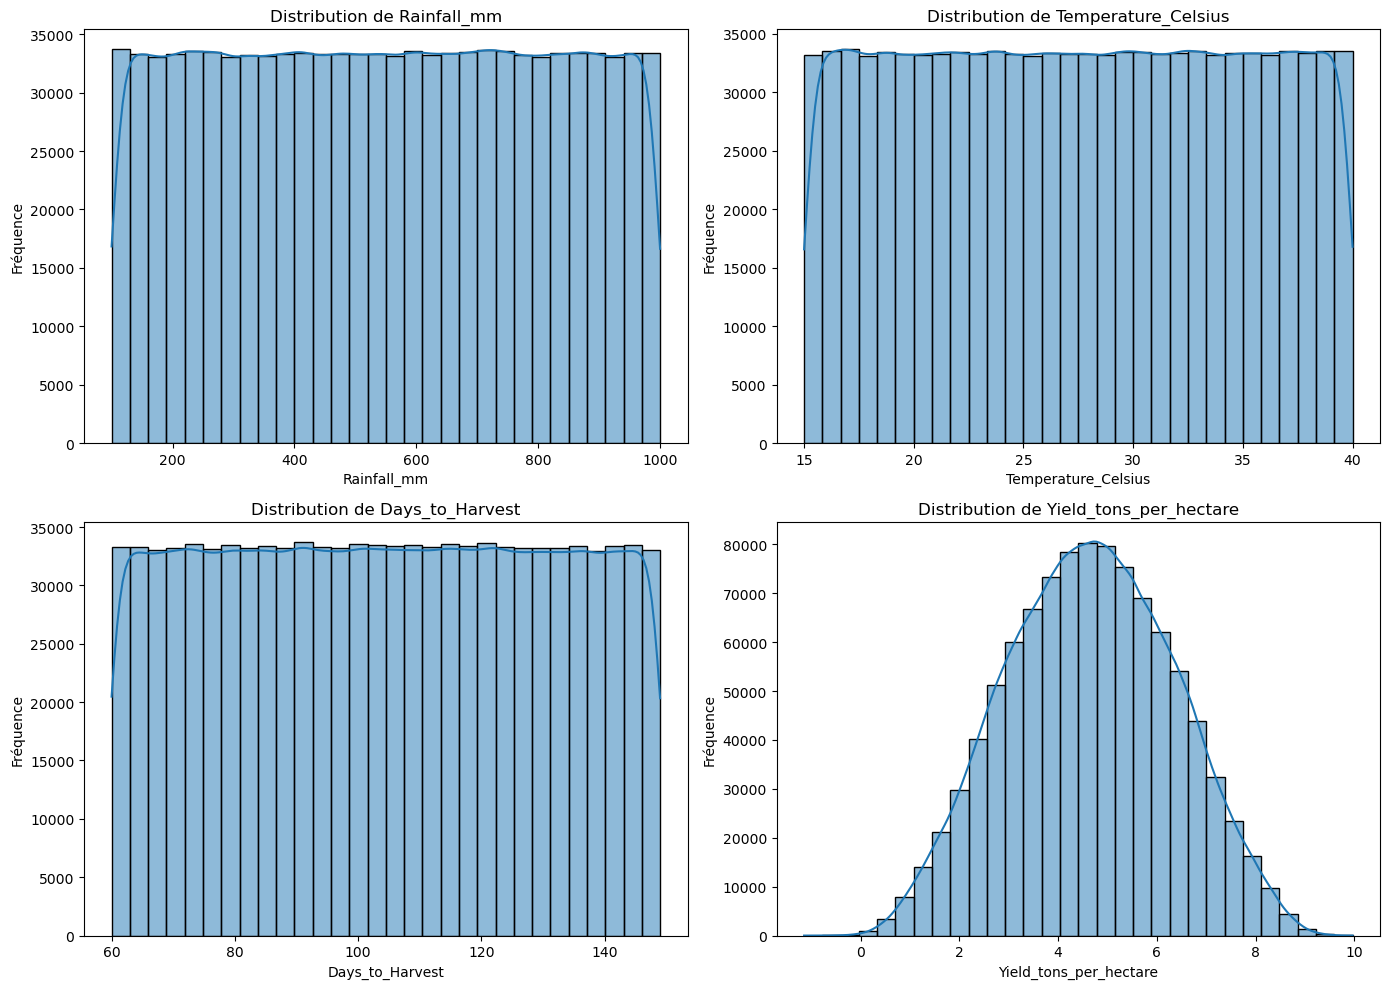

In [88]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(
        data=df_crop_yield,
        x=col,
        kde=True,
        bins=30,
        ax=ax
    )
    
    ax.set_title(f"Distribution de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Fréquence")

plt.tight_layout()
plt.show()

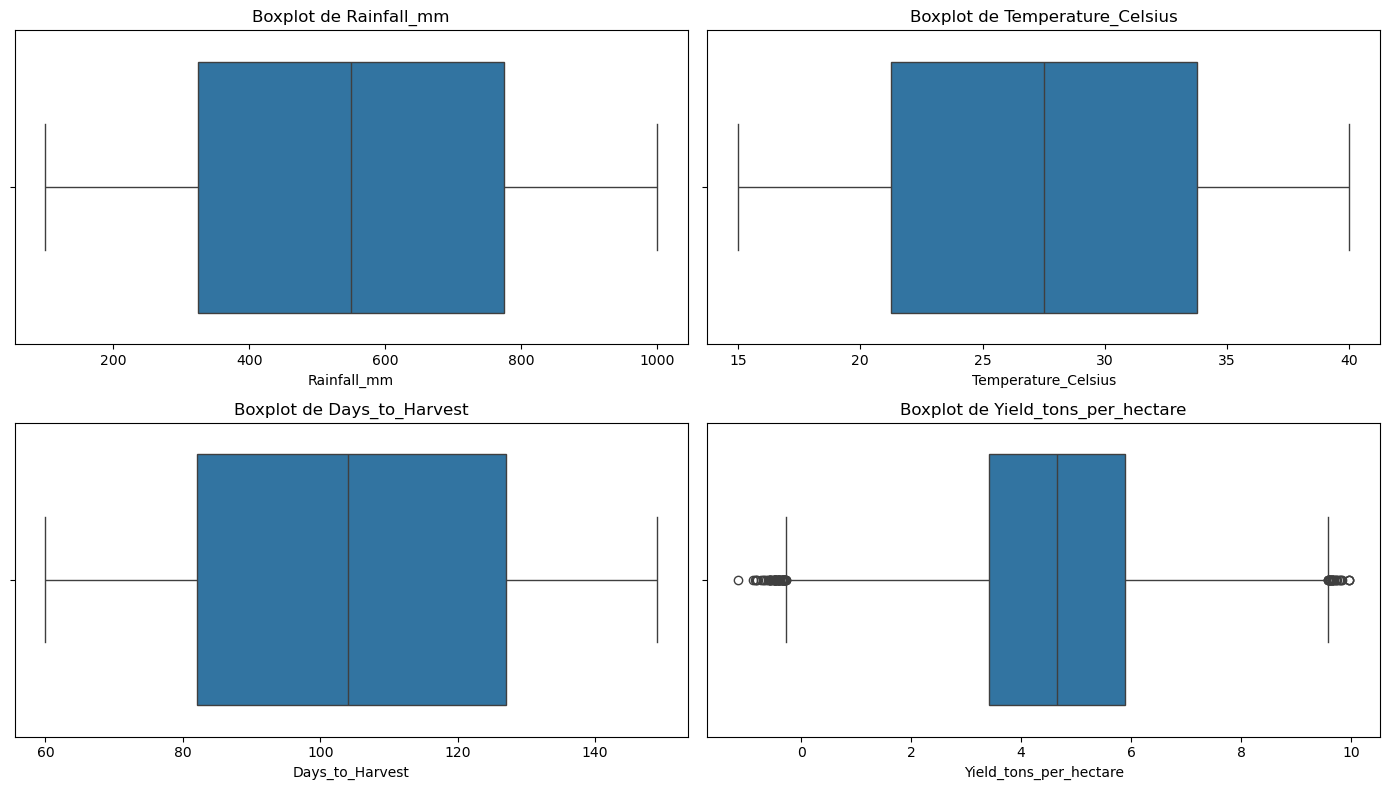

In [90]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(
        data=df_crop_yield,
        x=col,
        ax=ax
    )
    
    ax.set_title(f"Boxplot de {col}")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()

In [92]:
num_cols = [
    "Rainfall_mm",
    "Temperature_Celsius",
    "Days_to_Harvest",
    "Yield_tons_per_hectare"
]

# Valeur atypique : en dehors de [Q1 - 1,5 × IQR ; Q3 + 1,5 × IQR]

for col in num_cols:
    q1, q3 = df_crop_yield[col].quantile([0.25, 0.75])
    
    iqr = q3 - q1
    
    basse = q1 - 1.5 * iqr
    haute = q3 + 1.5 * iqr
    
    n = (
        (df_crop_yield[col] < basse) |
        (df_crop_yield[col] > haute)
    ).sum()
    
    pourcentage = n / len(df_crop_yield)
    
    print(
        f"{col:28} "
        f"{n:8d} atypiques "
        f"({pourcentage:.3%})   "
        f"bornes = [{basse:.2f}, {haute:.2f}]"
    )

Rainfall_mm                         0 atypiques (0.000%)   bornes = [-349.88, 1449.51]
Temperature_Celsius                 0 atypiques (0.000%)   bornes = [2.51, 52.50]
Days_to_Harvest                     0 atypiques (0.000%)   bornes = [14.50, 194.50]
Yield_tons_per_hectare             84 atypiques (0.008%)   bornes = [-0.27, 9.57]


### Correlation

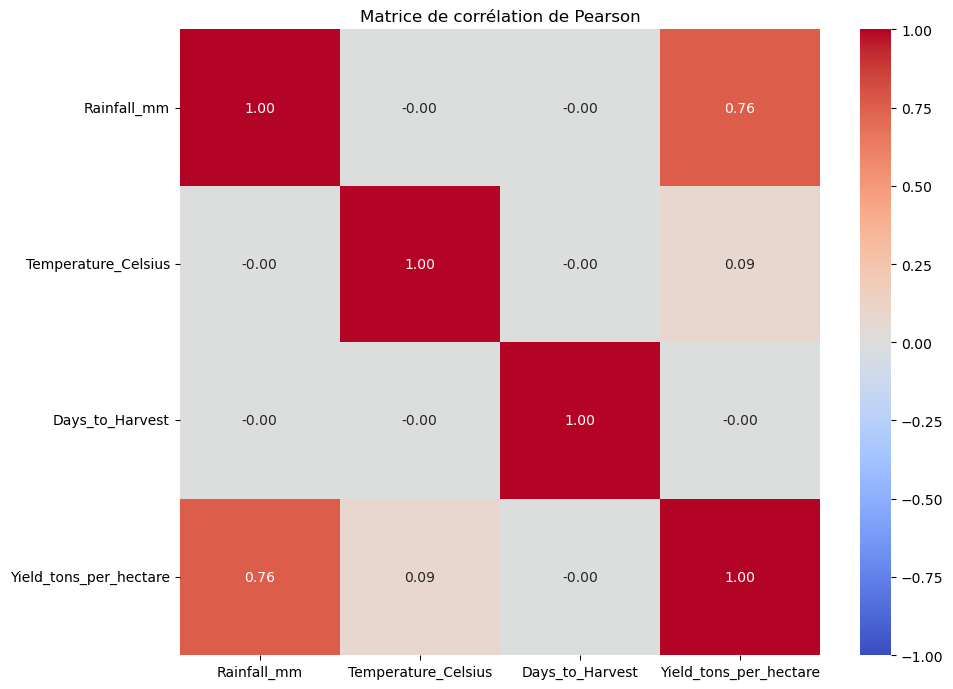

In [94]:
import matplotlib.pyplot as plt
import seaborn as sns

# Colonnes numériques
num_cols = [
    "Rainfall_mm",
    "Temperature_Celsius",
    "Days_to_Harvest",
    "Yield_tons_per_hectare"
]

# Calcul des corrélations de Pearson
corr = df_crop_yield[num_cols].corr(method="pearson")

# Affichage de la matrice
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Matrice de corrélation de Pearson")
plt.tight_layout()
plt.show()

In [98]:
correlation_yield = (
    df_crop_yield[num_cols]
    .corr(method="pearson")["Yield_tons_per_hectare"]
    .sort_values(ascending=False)
)

display(correlation_yield)

Yield_tons_per_hectare    1.000000
Rainfall_mm               0.764618
Temperature_Celsius       0.085565
Days_to_Harvest          -0.002591
Name: Yield_tons_per_hectare, dtype: float64

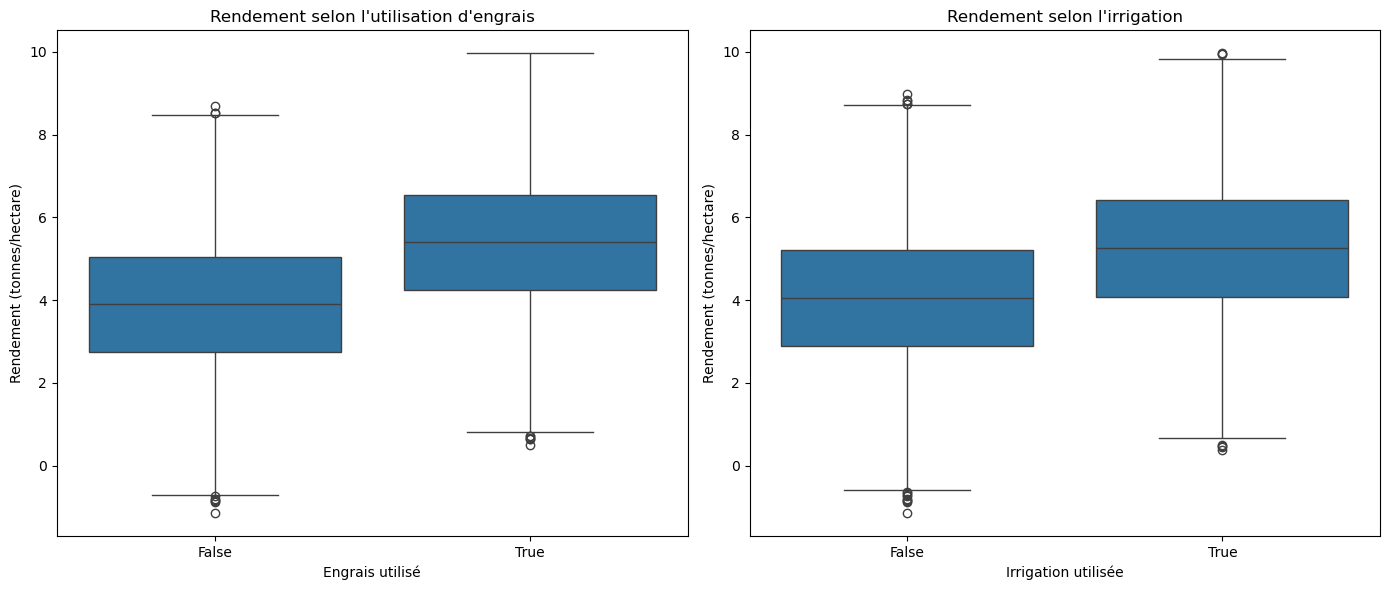

In [106]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(
    data=df_crop_yield,
    x="Fertilizer_Used",
    y="Yield_tons_per_hectare",
    ax=axes[0]
)

axes[0].set_title("Rendement selon l'utilisation d'engrais")
axes[0].set_xlabel("Engrais utilisé")
axes[0].set_ylabel("Rendement (tonnes/hectare)")


sns.boxplot(
    data=df_crop_yield,
    x="Irrigation_Used",
    y="Yield_tons_per_hectare",
    ax=axes[1]
)

axes[1].set_title("Rendement selon l'irrigation")
axes[1].set_xlabel("Irrigation utilisée")
axes[1].set_ylabel("Rendement (tonnes/hectare)")

plt.tight_layout()
plt.show()

In [118]:
# Trier les données par rendement décroissant
best_yields = df_crop_yield.sort_values(
    by="Yield_tons_per_hectare",
    ascending=False
)

# Afficher les 20 meilleurs rendements
display(best_yields.head(10))

,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
868145,South,Chalky,Rice,980.537954,37.263468,True,True,Rainy,80,9.963372
713988,West,Loam,Maize,977.575295,32.934272,True,True,Sunny,115,9.952983
905016,North,Chalky,Barley,874.775592,27.909656,True,True,Cloudy,102,9.949207
942403,South,Silt,Maize,987.281001,23.821032,True,True,Rainy,114,9.826285
465022,East,Sandy,Wheat,978.875813,35.301038,True,True,Rainy,143,9.802534
469963,North,Sandy,Cotton,967.070702,15.765251,True,True,Sunny,137,9.786272
866796,West,Chalky,Rice,980.380130,26.385247,True,True,Sunny,64,9.769839
572954,East,Loam,Barley,933.096993,39.445050,True,True,Cloudy,90,9.744646
11596,West,Peaty,Wheat,957.380991,36.324216,True,True,Sunny,73,9.727004
385993,East,Clay,Rice,977.530313,30.647480,True,True,Rainy,137,9.721110


### Analyse par culture

In [116]:
# Top 5 % des rendements
threshold = df_crop_yield["Yield_tons_per_hectare"].quantile(0.95)

top_5 = df_crop_yield[
    df_crop_yield["Yield_tons_per_hectare"] >= threshold
]

# Conditions des meilleurs rendements par culture
summary_by_crop = (
    top_5
    .groupby("Crop")
    .agg(
        rendement_moyen=("Yield_tons_per_hectare", "mean"),
        pluie_moyenne=("Rainfall_mm", "mean"),
        temperature_moyenne=("Temperature_Celsius", "mean"),
        jours_recolte_moyens=("Days_to_Harvest", "mean"),
        nombre_observations=("Yield_tons_per_hectare", "count")
    )
    .sort_values("rendement_moyen", ascending=False)
)

display(summary_by_crop)

,rendement_moyen,pluie_moyenne,temperature_moyenne,jours_recolte_moyens,nombre_observations
Crop,,,,,
Wheat,7.979787,895.220139,28.870095,104.133847,8308
Rice,7.976646,894.388259,28.917378,104.315386,8469
Maize,7.974139,895.241196,28.903575,104.455829,8218
Soybean,7.972711,894.928866,28.897202,104.013003,8383
Cotton,7.972479,894.670987,28.932128,104.628808,8338
Barley,7.969846,893.578034,28.956231,104.682279,8284


### Pesticides dataset

In [15]:
df_pesticides= pd.read_csv('pesticides.csv')

In [17]:
df_pesticides.columns

Index(['Domain', 'Area', 'Element', 'Item', 'Year', 'Unit', 'Value'], dtype='object')

In [128]:
df_pesticides.describe(include='all')

,Domain,Area,Element,Item,Year,Unit,Value
count,4349,4349,4349,4349,4349.000000,4349,4.349000e+03
unique,1,168,1,1,NaN,1,NaN
top,Pesticides Use,Albania,Use,Pesticides (total),NaN,tonnes of active ingredients,NaN
freq,4349,27,4349,4349,NaN,4349,NaN
mean,NaN,NaN,NaN,NaN,2003.138883,NaN,2.030334e+04
std,NaN,NaN,NaN,NaN,7.728044,NaN,1.177362e+05
min,NaN,NaN,NaN,NaN,1990.000000,NaN,0.000000e+00
25%,NaN,NaN,NaN,NaN,1996.000000,NaN,9.300000e+01
50%,NaN,NaN,NaN,NaN,2003.000000,NaN,1.137560e+03
75%,NaN,NaN,NaN,NaN,2010.000000,NaN,7.869000e+03


In [130]:
df_pesticides.isna().sum()

Domain     0
Area       0
Element    0
Item       0
Year       0
Unit       0
Value      0
dtype: int64

In [132]:
df_pesticides.dtypes

Domain      object
Area        object
Element     object
Item        object
Year         int64
Unit        object
Value      float64
dtype: object

In [134]:
df_pesticides.shape

(4349, 7)

In [136]:
df_pesticides.head(10)

,Domain,Area,Element,Item,Year,Unit,Value
0,Pesticides Use,Albania,Use,Pesticides (total),1990,tonnes of active ingredients,121.00
1,Pesticides Use,Albania,Use,Pesticides (total),1991,tonnes of active ingredients,121.00
2,Pesticides Use,Albania,Use,Pesticides (total),1992,tonnes of active ingredients,121.00
3,Pesticides Use,Albania,Use,Pesticides (total),1993,tonnes of active ingredients,121.00
4,Pesticides Use,Albania,Use,Pesticides (total),1994,tonnes of active ingredients,201.00
5,Pesticides Use,Albania,Use,Pesticides (total),1995,tonnes of active ingredients,251.00
6,Pesticides Use,Albania,Use,Pesticides (total),1996,tonnes of active ingredients,313.96
7,Pesticides Use,Albania,Use,Pesticides (total),1997,tonnes of active ingredients,376.93
8,Pesticides Use,Albania,Use,Pesticides (total),1998,tonnes of active ingredients,439.89
9,Pesticides Use,Albania,Use,Pesticides (total),1999,tonnes of active ingredients,502.86


In [261]:
df_pesticides['Domain'].unique()

array(['Pesticides Use'], dtype=object)

In [263]:
df_pesticides['Element'].unique()

array(['Use'], dtype=object)

In [265]:
df_pesticides['Item'].unique()

array(['Pesticides (total)'], dtype=object)

In [267]:
df_pesticides['Unit'].unique()

array(['tonnes of active ingredients'], dtype=object)

In [269]:
df_pesticides.rename(columns={'Value':'Pesticide_use_total_tonnes'}, inplace=True)

In [271]:
df_pesticides.head(10)

,Domain,Area,Element,Item,Year,Unit,Pesticide_use_total_tonnes
0,Pesticides Use,Albania,Use,Pesticides (total),1990,tonnes of active ingredients,121.00
1,Pesticides Use,Albania,Use,Pesticides (total),1991,tonnes of active ingredients,121.00
2,Pesticides Use,Albania,Use,Pesticides (total),1992,tonnes of active ingredients,121.00
3,Pesticides Use,Albania,Use,Pesticides (total),1993,tonnes of active ingredients,121.00
4,Pesticides Use,Albania,Use,Pesticides (total),1994,tonnes of active ingredients,201.00
5,Pesticides Use,Albania,Use,Pesticides (total),1995,tonnes of active ingredients,251.00
6,Pesticides Use,Albania,Use,Pesticides (total),1996,tonnes of active ingredients,313.96
7,Pesticides Use,Albania,Use,Pesticides (total),1997,tonnes of active ingredients,376.93
8,Pesticides Use,Albania,Use,Pesticides (total),1998,tonnes of active ingredients,439.89
9,Pesticides Use,Albania,Use,Pesticides (total),1999,tonnes of active ingredients,502.86


In [273]:
df_pesticides.drop(columns=['Domain','Element','Item', 'Unit'], inplace=True)

In [275]:
df_pesticides.head(10)

,Area,Year,Pesticide_use_total_tonnes
0,Albania,1990,121.00
1,Albania,1991,121.00
2,Albania,1992,121.00
3,Albania,1993,121.00
4,Albania,1994,201.00
5,Albania,1995,251.00
6,Albania,1996,313.96
7,Albania,1997,376.93
8,Albania,1998,439.89
9,Albania,1999,502.86


### Missing values

In [278]:
# Vérifier les valeurs manquantes
missing_pesticides = pd.DataFrame({
    "missing_count": df_pesticides.isna().sum(),
    "missing_percent": df_pesticides.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

display(missing_pesticides)

,missing_count,missing_percent
Area,0,0.0
Year,0,0.0
Pesticide_use_total_tonnes,0,0.0


### Doublons

In [281]:
# Nombre de lignes dupliquées
duplicates_pesticides = df_pesticides.duplicated().sum()

print("Nombre de doublons :", duplicates_pesticides)
print("Pourcentage de doublons :", 
      duplicates_pesticides / len(df_pesticides) * 100, "%")

Nombre de doublons : 0
Pourcentage de doublons : 0.0 %


In [283]:
# Sélection automatique des colonnes numériques
num_cols_pesticides = df_pesticides.select_dtypes(include="number").columns.tolist()

print("Colonnes numériques :", num_cols_pesticides)

outliers_pesticides = []

for col in num_cols_pesticides:
    q1 = df_pesticides[col].quantile(0.25)
    q3 = df_pesticides[col].quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    mask = (
        (df_pesticides[col] < lower_bound) |
        (df_pesticides[col] > upper_bound)
    )
    
    count = mask.sum()
    
    outliers_pesticides.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Borne basse": lower_bound,
        "Borne haute": upper_bound,
        "Nombre atypiques": count,
        "Pourcentage": count / len(df_pesticides) * 100
    })

outliers_pesticides = pd.DataFrame(outliers_pesticides)

display(outliers_pesticides)

Colonnes numériques : ['Year', 'Pesticide_use_total_tonnes']


,Variable,Q1,Q3,IQR,Borne basse,Borne haute,Nombre atypiques,Pourcentage
0,Year,1996.0,2010.0,14.0,1975.0,2031.0,0,0.000000
1,Pesticide_use_total_tonnes,93.0,7869.0,7776.0,-11571.0,19533.0,615,14.141182


In [285]:
for col in num_cols_pesticides:
    q1 = df_pesticides[col].quantile(0.25)
    q3 = df_pesticides[col].quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = df_pesticides[
        (df_pesticides[col] < lower_bound) |
        (df_pesticides[col] > upper_bound)
    ]
    
    print(f"\n===== {col} =====")
    print(f"Nombre de valeurs atypiques : {len(outliers)}")
    display(outliers.head(10))


===== Year =====
Nombre de valeurs atypiques : 0


,Area,Year,Pesticide_use_total_tonnes



===== Pesticide_use_total_tonnes =====
Nombre de valeurs atypiques : 615


,Area,Year,Pesticide_use_total_tonnes
108,Argentina,1990,26156.00
109,Argentina,1991,26156.00
110,Argentina,1992,26156.00
111,Argentina,1993,26156.00
112,Argentina,1994,30195.00
113,Argentina,1995,37842.00
114,Argentina,1996,54595.00
115,Argentina,1997,77691.00
116,Argentina,1998,62397.00
117,Argentina,1999,62831.39


### # Corrélation automatique des variables numériques pesticides

In [288]:
def correlation_matrix(df, name="df_pesticides"):
    num_cols = df.select_dtypes(include="number").columns.tolist()

    print(f"===== {name} =====")
    print("Variables numériques :", num_cols)

    corr = df[num_cols].corr(method="pearson")

    plt.figure(figsize=(12, 8))

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1
    )

    plt.title(f"Matrice de corrélation - {name}")
    plt.tight_layout()
    plt.show()

    return corr

===== Pesticides =====
Variables numériques : ['Year', 'Pesticide_use_total_tonnes']


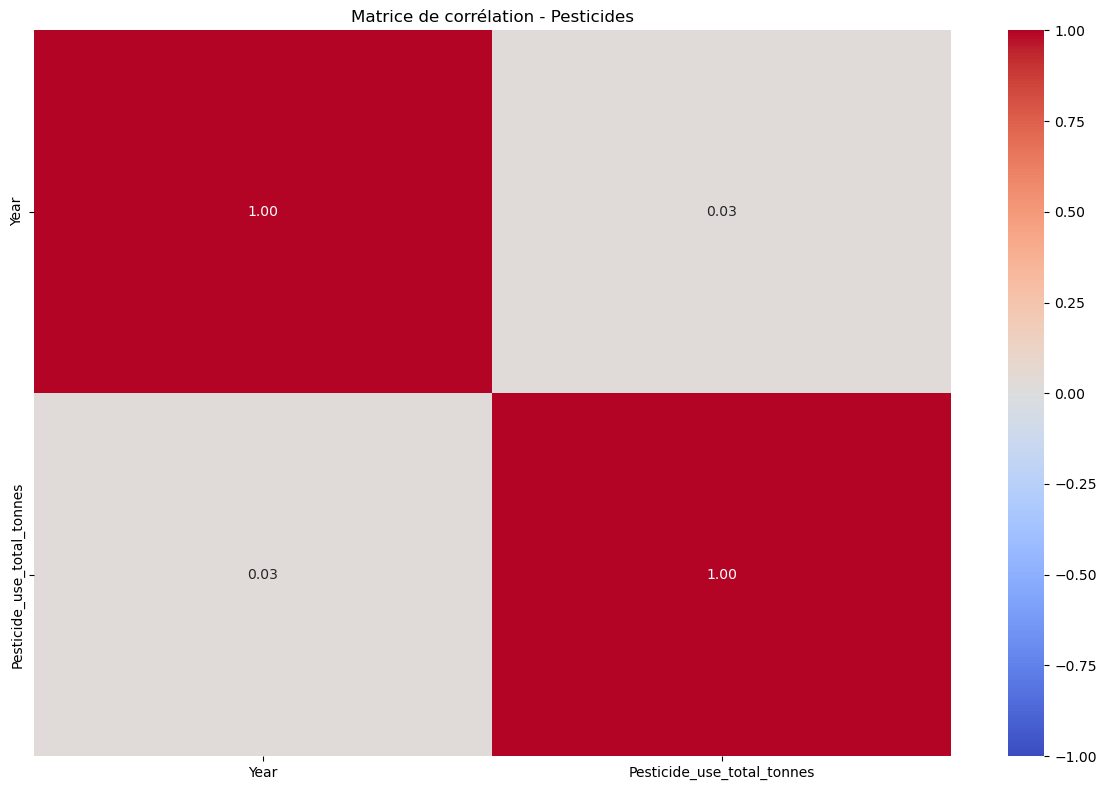

In [290]:
corr_pesticides = correlation_matrix(
    df_pesticides,
    "Pesticides"
)

### Rainfall 

In [19]:
df_rainfall= pd.read_csv('rainfall.csv')

In [160]:
df_rainfall.columns

Index([' Area', 'Year', 'average_rain_fall_mm_per_year'], dtype='object')

In [162]:
df_rainfall.describe(include='all')

,Area,Year,average_rain_fall_mm_per_year
count,6727,6727.000000,5953
unique,217,NaN,173
top,Afghanistan,NaN,630
freq,31,NaN,62
mean,NaN,2001.354839,NaN
std,NaN,9.530114,NaN
min,NaN,1985.000000,NaN
25%,NaN,1993.000000,NaN
50%,NaN,2001.000000,NaN
75%,NaN,2010.000000,NaN


In [165]:
df_rainfall.isna().sum()

 Area                              0
Year                               0
average_rain_fall_mm_per_year    774
dtype: int64

In [167]:
df_rainfall.dtypes

 Area                            object
Year                              int64
average_rain_fall_mm_per_year    object
dtype: object

In [169]:
df_rainfall.shape

(6727, 3)

#### Missing values

In [172]:
# Vérifier les valeurs manquantes
missing_rainfall = pd.DataFrame({
    "missing_count": df_rainfall.isna().sum(),
    "missing_percent": df_rainfall.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

display(missing_rainfall)

,missing_count,missing_percent
average_rain_fall_mm_per_year,774,11.505872
Area,0,0.000000
Year,0,0.000000


#### Doublon 

In [175]:
# Nombre de lignes dupliquées
duplicates_rainfall = df_rainfall.duplicated().sum()

print("Nombre de doublons :", duplicates_rainfall)
print("Pourcentage de doublons :", 
      duplicates_rainfall / len(df_rainfall) * 100, "%")

Nombre de doublons : 0
Pourcentage de doublons : 0.0 %


In [177]:
# Sélection automatique des colonnes numériques
num_cols_rainfall = df_rainfall.select_dtypes(include="number").columns.tolist()

print("Colonnes numériques :", num_cols_rainfall)

outliers_rainfall = []

for col in num_cols_rainfall:
    q1 = df_rainfall[col].quantile(0.25)
    q3 = df_rainfall[col].quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    mask = (
        (df_rainfall[col] < lower_bound) |
        (df_rainfall[col] > upper_bound)
    )
    
    count = mask.sum()
    
    outliers_rainfall.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Borne basse": lower_bound,
        "Borne haute": upper_bound,
        "Nombre atypiques": count,
        "Pourcentage": count / len(df_rainfall) * 100
    })

outliers_rainfall = pd.DataFrame(outliers_rainfall)

display(outliers_rainfall)

Colonnes numériques : ['Year']


,Variable,Q1,Q3,IQR,Borne basse,Borne haute,Nombre atypiques,Pourcentage
0,Year,1993.0,2010.0,17.0,1967.5,2035.5,0,0.0


#### Temp

In [21]:
df_temp= pd.read_csv('temp.csv')

In [187]:
df_temp.columns

Index(['year', 'country', 'avg_temp'], dtype='object')

In [189]:
df_temp.describe(include='all')

,year,country,avg_temp
count,71311.000000,71311,68764.000000
unique,NaN,137,NaN
top,NaN,United States,NaN
freq,NaN,11973,NaN
mean,1905.799007,NaN,16.183876
std,67.102099,NaN,7.592960
min,1743.000000,NaN,-14.350000
25%,1858.000000,NaN,9.750000
50%,1910.000000,NaN,16.140000
75%,1962.000000,NaN,23.762500


In [191]:
df_temp.isna().sum()

year           0
country        0
avg_temp    2547
dtype: int64

In [193]:
df_temp.shape

(71311, 3)

In [195]:
df_temp.dtypes

year          int64
country      object
avg_temp    float64
dtype: object

#### Missing values

In [198]:
# Vérifier les valeurs manquantes
missing_temp = pd.DataFrame({
    "missing_count": df_temp.isna().sum(),
    "missing_percent": df_temp.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

display(missing_temp)

,missing_count,missing_percent
avg_temp,2547,3.571679
year,0,0.000000
country,0,0.000000


#### Doublon 

In [201]:
# Nombre de lignes dupliquées
duplicates_temp = df_temp.duplicated().sum()

print("Nombre de doublons :", duplicates_temp)
print("Pourcentage de doublons :", 
      duplicates_temp / len(df_temp) * 100, "%")

Nombre de doublons : 6958
Pourcentage de doublons : 9.757260450701857 %


In [227]:
# Sélection automatique des colonnes numériques
num_cols_temp = df_temp.select_dtypes(include="number").columns.tolist()

print("Colonnes numériques :", num_cols_temp)

outliers_temp = []

for col in num_cols_temp:
    q1 = df_temp[col].quantile(0.25)
    q3 = df_temp[col].quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    mask = (
        (df_temp[col] < lower_bound) |
        (df_temp[col] > upper_bound)
    )
    
    count = mask.sum()
    
    outliers_temp.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Borne basse": lower_bound,
        "Borne haute": upper_bound,
        "Nombre atypiques": count,
        "Pourcentage": count / len(df_temp) * 100
    })

outliers_temp = pd.DataFrame(outliers_temp)

display(outliers_temp)

Colonnes numériques : ['year', 'avg_temp']


,Variable,Q1,Q3,IQR,Borne basse,Borne haute,Nombre atypiques,Pourcentage
0,year,1858.00,1962.0000,104.0000,1702.00000,2118.00000,0,0.000000
1,avg_temp,9.75,23.7625,14.0125,-11.26875,44.78125,2,0.002805


#### yield_df

In [23]:
df_yield_df= pd.read_csv('yield_df.csv')

In [320]:
df_yield_df.columns

Index(['Unnamed: 0', 'Area', 'Item', 'Year', 'hg/ha_yield',
       'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp'],
      dtype='object')

In [322]:
df_yield_df.describe(include='all')

,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
count,28242.000000,28242,28242,28242.000000,28242.000000,28242.00000,28242.000000,28242.000000
unique,NaN,101,10,NaN,NaN,NaN,NaN,NaN
top,NaN,India,Potatoes,NaN,NaN,NaN,NaN,NaN
freq,NaN,4048,4276,NaN,NaN,NaN,NaN,NaN
mean,14120.500000,NaN,NaN,2001.544296,77053.332094,1149.05598,37076.909344,20.542627
std,8152.907488,NaN,NaN,7.051905,84956.612897,709.81215,59958.784665,6.312051
min,0.000000,NaN,NaN,1990.000000,50.000000,51.00000,0.040000,1.300000
25%,7060.250000,NaN,NaN,1995.000000,19919.250000,593.00000,1702.000000,16.702500
50%,14120.500000,NaN,NaN,2001.000000,38295.000000,1083.00000,17529.440000,21.510000
75%,21180.750000,NaN,NaN,2008.000000,104676.750000,1668.00000,48687.880000,26.000000


In [324]:
df_yield_df.isna().sum()

Unnamed: 0                       0
Area                             0
Item                             0
Year                             0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64

In [326]:
df_yield_df.dtypes

Unnamed: 0                         int64
Area                              object
Item                              object
Year                               int64
hg/ha_yield                        int64
average_rain_fall_mm_per_year    float64
pesticides_tonnes                float64
avg_temp                         float64
dtype: object

In [328]:
df_yield_df.shape

(28242, 8)

In [332]:
df_yield_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Unnamed: 0                     28242 non-null  int64  
 1   Area                           28242 non-null  object 
 2   Item                           28242 non-null  object 
 3   Year                           28242 non-null  int64  
 4   hg/ha_yield                    28242 non-null  int64  
 5   average_rain_fall_mm_per_year  28242 non-null  float64
 6   pesticides_tonnes              28242 non-null  float64
 7   avg_temp                       28242 non-null  float64
dtypes: float64(3), int64(3), object(2)
memory usage: 1.7+ MB


In [334]:
print(df_yield_df["Unnamed: 0"].head(10))
print(df_yield_df["Unnamed: 0"].nunique())
print(len(df_yield_df))

0    0
1    1
2    2
3    3
4    4
5    5
6    6
7    7
8    8
9    9
Name: Unnamed: 0, dtype: int64
28242
28242


In [336]:
df_yield_df.drop(columns=['Unnamed: 0'], inplace=True)

#### Missing values 

In [339]:
# Vérifier les valeurs manquantes
missing_yield_df = pd.DataFrame({
    "missing_count": df_yield_df.isna().sum(),
    "missing_percent": df_yield_df.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

display(missing_yield_df)

,missing_count,missing_percent
Area,0,0.0
Item,0,0.0
Year,0,0.0
hg/ha_yield,0,0.0
average_rain_fall_mm_per_year,0,0.0
pesticides_tonnes,0,0.0
avg_temp,0,0.0


#### Doublons

In [342]:
# Nombre de lignes dupliquées
duplicates_yield_df = df_yield_df.duplicated().sum()

print("Nombre de doublons :", duplicates_yield_df)
print("Pourcentage de doublons :", 
      duplicates_yield_df / len(df_yield_df) * 100, "%")

Nombre de doublons : 2310
Pourcentage de doublons : 8.17930741448906 %


In [344]:
# Sélection automatique des colonnes numériques
num_cols_yield_df = df_yield_df.select_dtypes(include="number").columns.tolist()

print("Colonnes numériques :", num_cols_yield_df)

outliers_yield_df = []

for col in num_cols_yield_df:
    q1 = df_yield_df[col].quantile(0.25)
    q3 = df_yield_df[col].quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    mask = (
        (df_yield_df[col] < lower_bound) |
        (df_yield_df[col] > upper_bound)
    )
    
    count = mask.sum()
    
    outliers_yield_df.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Borne basse": lower_bound,
        "Borne haute": upper_bound,
        "Nombre atypiques": count,
        "Pourcentage": count / len(df_yield_df) * 100
    })

outliers_yield_df = pd.DataFrame(outliers_yield_df)

display(outliers_yield_df)

Colonnes numériques : ['Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']


,Variable,Q1,Q3,IQR,Borne basse,Borne haute,Nombre atypiques,Pourcentage
0,Year,1995.0000,2008.00,13.0000,1975.50000,2027.50000,0,0.000000
1,hg/ha_yield,19919.2500,104676.75,84757.5000,-107217.00000,231813.00000,2059,7.290560
2,average_rain_fall_mm_per_year,593.0000,1668.00,1075.0000,-1019.50000,3280.50000,0,0.000000
3,pesticides_tonnes,1702.0000,48687.88,46985.8800,-68776.82000,119166.70000,1418,5.020891
4,avg_temp,16.7025,26.00,9.2975,2.75625,39.94625,34,0.120388


#### Correlation matrix yield_df

In [347]:
def correlation_matrix(df, name="df_yield_df"):
    num_cols = df.select_dtypes(include="number").columns.tolist()

    print(f"===== {name} =====")
    print("Variables numériques :", num_cols)

    corr = df[num_cols].corr(method="pearson")

    plt.figure(figsize=(12, 8))

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1
    )

    plt.title(f"Matrice de corrélation - {name}")
    plt.tight_layout()
    plt.show()

    return corr

===== Yield_df =====
Variables numériques : ['Year', 'hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']


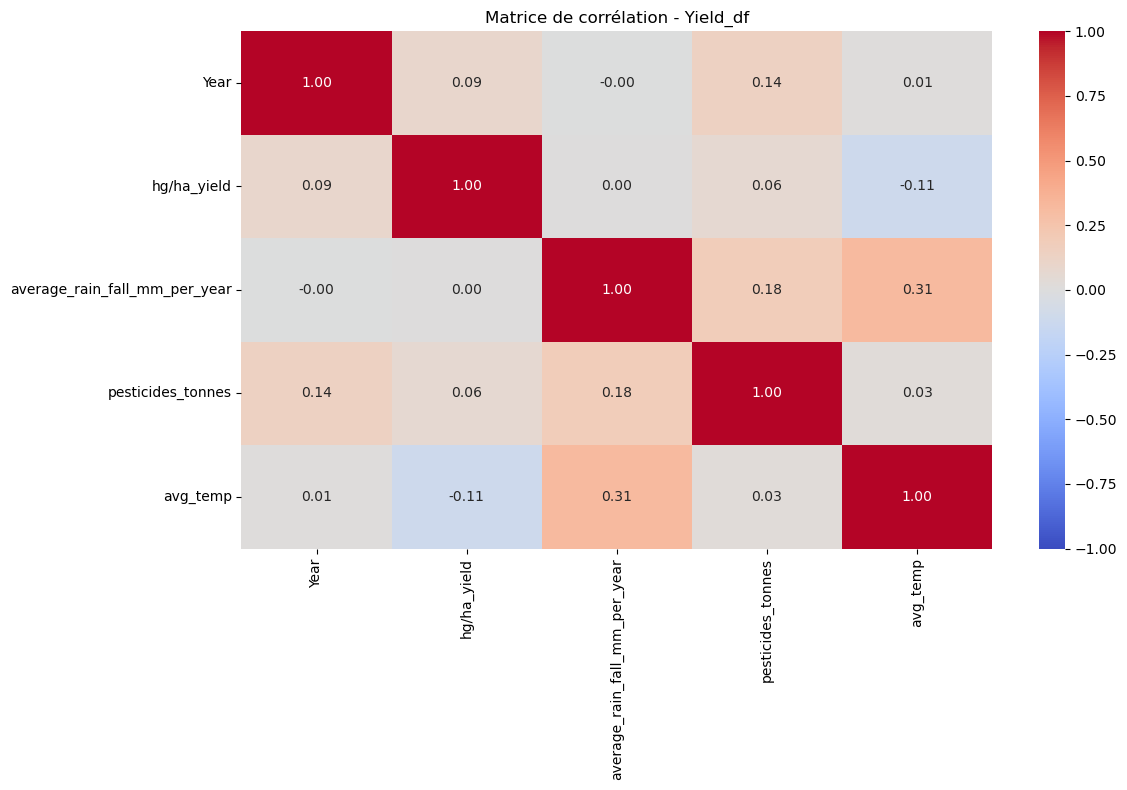

In [349]:
corr_yield_df = correlation_matrix(
    df_yield_df,
    "Yield_df"
)

#### Yield

In [43]:
df_yield= pd.read_csv('yield.csv')

In [45]:
df_yield.columns

Index(['Domain Code', 'Domain', 'Area Code', 'Area', 'Element Code', 'Element',
       'Item Code', 'Item', 'Year Code', 'Year', 'Unit', 'Value'],
      dtype='object')

In [47]:
df_yield.describe(include='all')

,Domain Code,Domain,Area Code,Area,Element Code,Element,Item Code,Item,Year Code,Year,Unit,Value
count,56717,56717,56717.000000,56717,56717.0,56717,56717.000000,56717,56717.000000,56717.000000,56717,56717.000000
unique,1,1,NaN,212,NaN,1,NaN,10,NaN,NaN,1,NaN
top,QC,Crops,NaN,United Republic of Tanzania,NaN,Yield,NaN,Maize,NaN,NaN,hg/ha,NaN
freq,56717,56717,NaN,560,NaN,56717,NaN,8631,NaN,NaN,56717,NaN
mean,NaN,NaN,125.650422,NaN,5419.0,NaN,111.611651,NaN,1989.669570,1989.669570,NaN,62094.660084
std,NaN,NaN,75.120195,NaN,0.0,NaN,101.278435,NaN,16.133198,16.133198,NaN,67835.932856
min,NaN,NaN,1.000000,NaN,5419.0,NaN,15.000000,NaN,1961.000000,1961.000000,NaN,0.000000
25%,NaN,NaN,58.000000,NaN,5419.0,NaN,56.000000,NaN,1976.000000,1976.000000,NaN,15680.000000
50%,NaN,NaN,122.000000,NaN,5419.0,NaN,116.000000,NaN,1991.000000,1991.000000,NaN,36744.000000
75%,NaN,NaN,184.000000,NaN,5419.0,NaN,125.000000,NaN,2004.000000,2004.000000,NaN,86213.000000


In [49]:
df_yield.head(10)

,Domain Code,Domain,Area Code,Area,Element Code,Element,Item Code,Item,Year Code,Year,Unit,Value
0,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1961,1961,hg/ha,14000
1,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1962,1962,hg/ha,14000
2,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1963,1963,hg/ha,14260
3,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1964,1964,hg/ha,14257
4,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1965,1965,hg/ha,14400
5,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1966,1966,hg/ha,14400
6,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1967,1967,hg/ha,14144
7,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1968,1968,hg/ha,17064
8,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1969,1969,hg/ha,17177
9,QC,Crops,2,Afghanistan,5419,Yield,56,Maize,1970,1970,hg/ha,14757


In [51]:
df_yield.isna().sum()

Domain Code     0
Domain          0
Area Code       0
Area            0
Element Code    0
Element         0
Item Code       0
Item            0
Year Code       0
Year            0
Unit            0
Value           0
dtype: int64

In [53]:
df_yield.dtypes

Domain Code     object
Domain          object
Area Code        int64
Area            object
Element Code     int64
Element         object
Item Code        int64
Item            object
Year Code        int64
Year             int64
Unit            object
Value            int64
dtype: object

In [55]:
df_yield.shape

(56717, 12)

In [57]:
print(df_yield['Domain Code'].unique())
print(df_yield['Domain'].unique())
print(df_yield['Element Code'].unique())
print(df_yield['Element'].unique())
print(df_yield['Unit'].unique())

['QC']
['Crops']
[5419]
['Yield']
['hg/ha']


In [59]:
df_yield.rename(columns={'Value':'Yield_crops_hg_per_ha'}, inplace=True)

In [61]:
df_yield.drop(columns=['Domain Code','Domain','Element Code','Element','Unit', 'Year Code'], inplace=True)

In [63]:
df_yield.head(10)

,Area Code,Area,Item Code,Item,Year,Yield_crops_hg_per_ha
0,2,Afghanistan,56,Maize,1961,14000
1,2,Afghanistan,56,Maize,1962,14000
2,2,Afghanistan,56,Maize,1963,14260
3,2,Afghanistan,56,Maize,1964,14257
4,2,Afghanistan,56,Maize,1965,14400
5,2,Afghanistan,56,Maize,1966,14400
6,2,Afghanistan,56,Maize,1967,14144
7,2,Afghanistan,56,Maize,1968,17064
8,2,Afghanistan,56,Maize,1969,17177
9,2,Afghanistan,56,Maize,1970,14757


#### Missing values

In [66]:
# Vérifier les valeurs manquantes
missing_yield = pd.DataFrame({
    "missing_count": df_yield.isna().sum(),
    "missing_percent": df_yield.isna().mean() * 100
}).sort_values("missing_percent", ascending=False)

display(missing_yield)

,missing_count,missing_percent
Area Code,0,0.0
Area,0,0.0
Item Code,0,0.0
Item,0,0.0
Year,0,0.0
Yield_crops_hg_per_ha,0,0.0


### Doublons 

In [69]:
# Nombre de lignes dupliquées
duplicates_yield = df_yield.duplicated().sum()

print("Nombre de doublons :", duplicates_yield)
print("Pourcentage de doublons :", 
      duplicates_yield / len(df_yield) * 100, "%")

Nombre de doublons : 0
Pourcentage de doublons : 0.0 %


In [71]:
# Sélection automatique des colonnes numériques
num_cols_yield = df_yield.select_dtypes(include="number").columns.tolist()

print("Colonnes numériques :", num_cols_yield)

outliers_yield = []

for col in num_cols_yield:
    q1 = df_yield[col].quantile(0.25)
    q3 = df_yield[col].quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    mask = (
        (df_yield[col] < lower_bound) |
        (df_yield[col] > upper_bound)
    )
    
    count = mask.sum()
    
    outliers_yield.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Borne basse": lower_bound,
        "Borne haute": upper_bound,
        "Nombre atypiques": count,
        "Pourcentage": count / len(df_yield) * 100
    })

outliers_yield = pd.DataFrame(outliers_yield)

display(outliers_yield)

Colonnes numériques : ['Area Code', 'Item Code', 'Year', 'Yield_crops_hg_per_ha']


,Variable,Q1,Q3,IQR,Borne basse,Borne haute,Nombre atypiques,Pourcentage
0,Area Code,58.0,184.0,126.0,-131.0,373.0,0,0.000000
1,Item Code,56.0,125.0,69.0,-47.5,228.5,6846,12.070455
2,Year,1976.0,2004.0,28.0,1934.0,2046.0,0,0.000000
3,Yield_crops_hg_per_ha,15680.0,86213.0,70533.0,-90119.5,192012.5,3169,5.587390


### Correlation matrix yield

In [74]:
def correlation_matrix(df, name="df_yield"):
    num_cols = df.select_dtypes(include="number").columns.tolist()

    print(f"===== {name} =====")
    print("Variables numériques :", num_cols)

    corr = df[num_cols].corr(method="pearson")

    plt.figure(figsize=(12, 8))

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1
    )

    plt.title(f"Matrice de corrélation - {name}")
    plt.tight_layout()
    plt.show()

    return corr

===== Yield =====
Variables numériques : ['Area Code', 'Item Code', 'Year', 'Yield_crops_hg_per_ha']


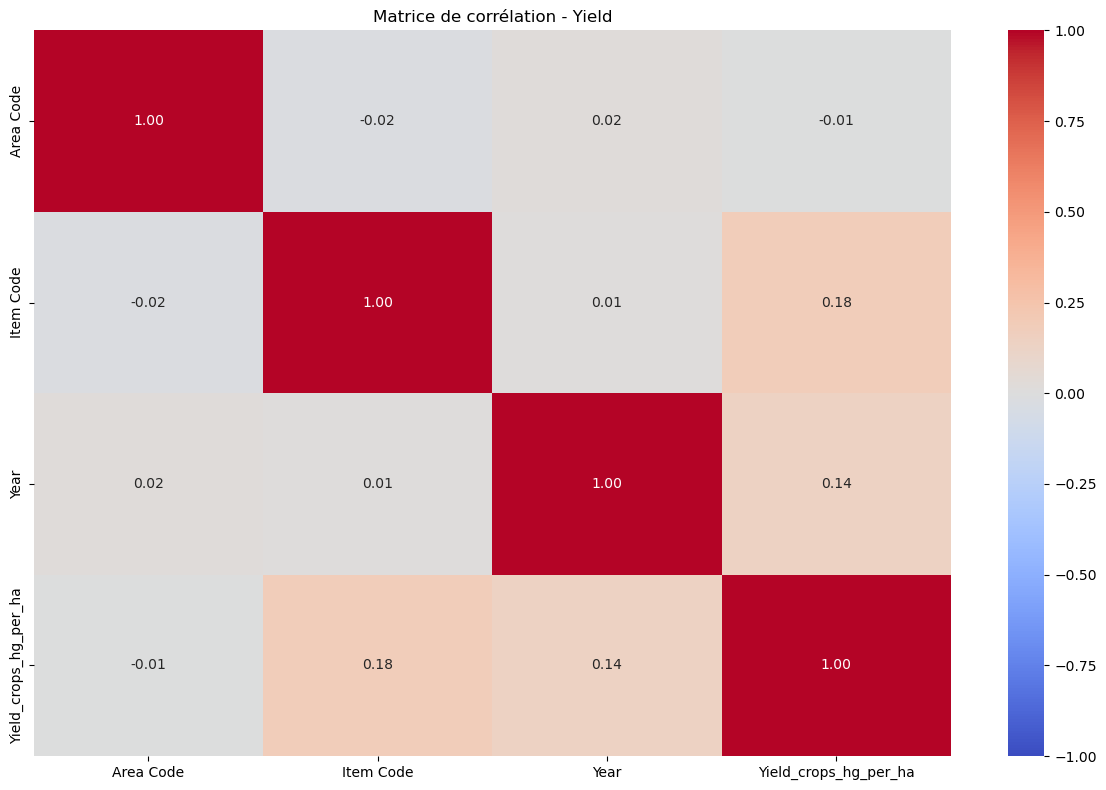

In [76]:
corr_yield = correlation_matrix(
    df_yield,
    "Yield"
)

## Fusion des données

#### df_yield & df_yield_df

In [80]:
df_yield_df.head(5)

,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [82]:
print("Année min :", df_yield_df["Year"].min())
print("Année max :", df_yield_df["Year"].max())

print("\nAnnées disponibles :")
print(sorted(df_yield_df["Year"].unique()))

Année min : 1990
Année max : 2013

Années disponibles :
[1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013]


In [84]:
df_yield.head(5)

,Area Code,Area,Item Code,Item,Year,Yield_crops_hg_per_ha
0,2,Afghanistan,56,Maize,1961,14000
1,2,Afghanistan,56,Maize,1962,14000
2,2,Afghanistan,56,Maize,1963,14260
3,2,Afghanistan,56,Maize,1964,14257
4,2,Afghanistan,56,Maize,1965,14400


In [86]:
print("Année min :", df_yield["Year"].min())
print("Année max :", df_yield["Year"].max())

print("\nAnnées disponibles :")
print(sorted(df_yield["Year"].unique()))

Année min : 1961
Année max : 2016

Années disponibles :
[1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016]


In [88]:
# Définir la période souhaitée
start_year = 1990
end_year = 2013

# Filtrer le dataset de rendement
df_yield = df_yield[
    df_yield["Year"].between(start_year, end_year)
].copy()

# Filtrer le deuxième dataset
df_yield_df = df_yield_df[
    df_yield_df["Year"].between(start_year, end_year)
].copy()

# Vérifier les résultats
print("df_yield :", df_yield.shape)
print("Période :", df_yield["Year"].min(), "-", df_yield["Year"].max())

print("\ndf_yield_df :", df_yield_df.shape)
print("Période :", df_yield_df["Year"].min(), "-", df_yield_df["Year"].max())

df_yield : (26040, 6)
Période : 1990 - 2013

df_yield_df : (28242, 7)
Période : 1990 - 2013


In [90]:
keys = ["Area", "Year", "Item"]

print(
    "Doublons dans df_yield :",
    df_yield.duplicated(subset=keys).sum()
)

print(
    "Doublons dans df_yield_df :",
    df_yield_df.duplicated(subset=keys).sum()
)

Doublons dans df_yield : 0
Doublons dans df_yield_df : 15112


In [92]:
keys = ["Area", "Year", "Item"]

keys_yield = df_yield[keys].drop_duplicates()
keys_yield_df = df_yield_df[keys].drop_duplicates()

matched_keys = keys_yield.merge(
    keys_yield_df,
    on=keys,
    how="inner"
)

print("Clés uniques dans df_yield :", len(keys_yield))
print("Clés uniques dans df_yield_df :", len(keys_yield_df))
print("Clés communes :", len(matched_keys))

print(
    "Taux de correspondance :",
    round(len(matched_keys) / len(keys_yield) * 100, 2),
    "%"
)

Clés uniques dans df_yield : 26040
Clés uniques dans df_yield_df : 13130
Clés communes : 13130
Taux de correspondance : 50.42 %


In [94]:
df_yield_final = df_yield.merge(df_yield_df, on=['Area', 'Year', 'Item'], how='inner')

In [96]:
df_yield_final.head(10)

,Area Code,Area,Item Code,Item,Year,Yield_crops_hg_per_ha,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,3,Albania,56,Maize,1990,36613,36613,1485.0,121.00,16.37
1,3,Albania,56,Maize,1991,29068,29068,1485.0,121.00,15.36
2,3,Albania,56,Maize,1992,24876,24876,1485.0,121.00,16.06
3,3,Albania,56,Maize,1993,24185,24185,1485.0,121.00,16.05
4,3,Albania,56,Maize,1994,25848,25848,1485.0,201.00,16.96
5,3,Albania,56,Maize,1995,31300,31300,1485.0,251.00,15.67
6,3,Albania,56,Maize,1996,32604,32604,1485.0,313.96,15.64
7,3,Albania,56,Maize,1997,31862,31862,1485.0,376.93,15.90
8,3,Albania,56,Maize,1998,33416,33416,1485.0,439.89,16.27
9,3,Albania,56,Maize,1999,37455,37455,1485.0,502.86,16.57


In [98]:
df_yield_final.shape

(28242, 10)

In [100]:
df_yield_final.isna().sum()

Area Code                        0
Area                             0
Item Code                        0
Item                             0
Year                             0
Yield_crops_hg_per_ha            0
hg/ha_yield                      0
average_rain_fall_mm_per_year    0
pesticides_tonnes                0
avg_temp                         0
dtype: int64

In [102]:
df_yield_final.drop(columns=['hg/ha_yield'], inplace=True)

In [104]:
df_yield_final.shape

(28242, 9)

#### Jointure df_yield_final & df_pesticides

In [107]:
df_pesticides.head(5)

,Domain,Area,Element,Item,Year,Unit,Value
0,Pesticides Use,Albania,Use,Pesticides (total),1990,tonnes of active ingredients,121.0
1,Pesticides Use,Albania,Use,Pesticides (total),1991,tonnes of active ingredients,121.0
2,Pesticides Use,Albania,Use,Pesticides (total),1992,tonnes of active ingredients,121.0
3,Pesticides Use,Albania,Use,Pesticides (total),1993,tonnes of active ingredients,121.0
4,Pesticides Use,Albania,Use,Pesticides (total),1994,tonnes of active ingredients,201.0


In [109]:
df_pesticides.rename(columns={'Value':'Pesticide_totale_use_tonnes'}, inplace=True)

In [111]:
df_pesticides.drop(columns=['Domain','Element','Item','Unit'], inplace=True)

In [113]:
df_pesticides.head(5)

,Area,Year,Pesticide_totale_use_tonnes
0,Albania,1990,121.0
1,Albania,1991,121.0
2,Albania,1992,121.0
3,Albania,1993,121.0
4,Albania,1994,201.0


In [115]:
yield_final_plus_pesticides = df_yield_final.merge(df_pesticides, on=['Area', 'Year'], how='inner')

In [117]:
yield_final_plus_pesticides.head(5)

,Area Code,Area,Item Code,Item,Year,Yield_crops_hg_per_ha,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp,Pesticide_totale_use_tonnes
0,3,Albania,56,Maize,1990,36613,1485.0,121.0,16.37,121.0
1,3,Albania,56,Maize,1991,29068,1485.0,121.0,15.36,121.0
2,3,Albania,56,Maize,1992,24876,1485.0,121.0,16.06,121.0
3,3,Albania,56,Maize,1993,24185,1485.0,121.0,16.05,121.0
4,3,Albania,56,Maize,1994,25848,1485.0,201.0,16.96,201.0


In [119]:
yield_final_plus_pesticides.drop(columns=['pesticides_tonnes'], inplace=True)

In [121]:
yield_final_plus_pesticides.head(5)

,Area Code,Area,Item Code,Item,Year,Yield_crops_hg_per_ha,average_rain_fall_mm_per_year,avg_temp,Pesticide_totale_use_tonnes
0,3,Albania,56,Maize,1990,36613,1485.0,16.37,121.0
1,3,Albania,56,Maize,1991,29068,1485.0,15.36,121.0
2,3,Albania,56,Maize,1992,24876,1485.0,16.06,121.0
3,3,Albania,56,Maize,1993,24185,1485.0,16.05,121.0
4,3,Albania,56,Maize,1994,25848,1485.0,16.96,201.0


In [123]:
yield_final_plus_pesticides['Item'].value_counts()

Item
Potatoes                4276
Maize                   4121
Wheat                   3857
Rice, paddy             3388
Soybeans                3223
Sorghum                 3039
Sweet potatoes          2890
Cassava                 2045
Yams                     847
Plantains and others     556
Name: count, dtype: int64

In [133]:
def histogram_graphic(df, x, title, xlabel, ylabel):
    plt.figure(figsize=(10, 6))
    
    sns.histplot(data=df, x=x, bins=30, kde=True)
    
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

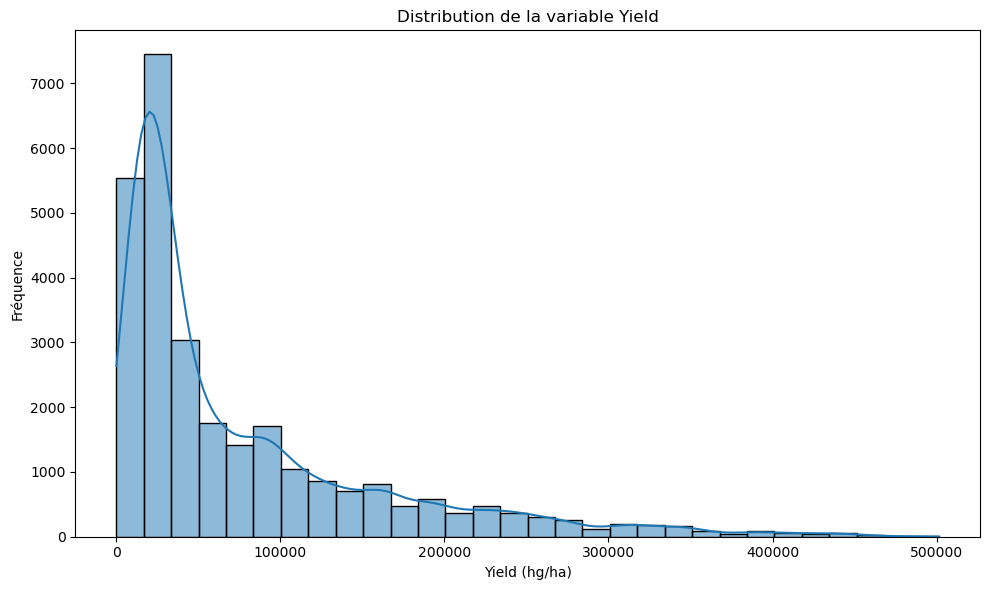

In [129]:
histogram_graphic(
    df=yield_final_plus_pesticides,
    x="Yield_crops_hg_per_ha",
    title="Distribution de la variable Yield",
    xlabel="Yield (hg/ha)",
    ylabel="Fréquence"
)

In [141]:
# Vérifier quels DataFrames existent réellement
print("yield_final_plus_pesticides :", 'yield_final_plus_pesticides' in globals())
print("pesticides                  :", 'pesticides' in globals())
print("rainfall                    :", 'rainfall' in globals())
print("temp                        :", 'temp' in globals())
print("yield_raw                   :", 'yield_raw' in globals())

yield_final_plus_pesticides : True
pesticides                  : False
rainfall                    : False
temp                        : False
yield_raw                   : False


In [145]:
# ============================================================
# VÉRIFICATION STRUCTURELLE DE yield_final_plus_pesticides
# ============================================================

df = yield_final_plus_pesticides.copy()

# ------------------------------------------------------------
# 0. NORMALISATION DES NOMS DE COLONNES
# ------------------------------------------------------------

df.columns = df.columns.str.strip()

print("=" * 70)
print("0. COLONNES DU DATASET")
print("=" * 70)

print(list(df.columns))


# ============================================================
# 1. COUVERTURE TEMPORELLE
# ============================================================

print("\n" + "=" * 70)
print("1. COUVERTURE TEMPORELLE")
print("=" * 70)

annees = sorted(df['Year'].dropna().unique())

print(
    f"yield_final_plus_pesticides — années : {annees}"
)

print(
    f"Année minimale : {df['Year'].min()}"
)

print(
    f"Année maximale : {df['Year'].max()}"
)

print(
    f"Nombre d'années : {df['Year'].nunique()}"
)


# ============================================================
# 2. COUVERTURE GÉOGRAPHIQUE
# ============================================================

print("\n" + "=" * 70)
print("2. COUVERTURE GÉOGRAPHIQUE")
print("=" * 70)

pays = (
    df['Area']
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
)

print(
    f"Nombre de pays : {len(pays)}"
)

print(
    f"Pays : {sorted(pays)}"
)


# ============================================================
# 3. CULTURES PRÉSENTES
# ============================================================

print("\n" + "=" * 70)
print("3. CULTURES PRÉSENTES")
print("=" * 70)

cultures = sorted(
    df['Item']
    .dropna()
    .astype(str)
    .str.strip()
    .unique()
)

print(
    f"Nombre de cultures : {len(cultures)}"
)

print(
    f"Cultures : {cultures}"
)


# ============================================================
# 4. VÉRIFICATION DES VRAIES VARIABLES
# ============================================================

print("\n" + "=" * 70)
print("4. VARIABLES DU DATASET FINAL")
print("=" * 70)

variables_attendues = {
    'Area': 'Pays',
    'Year': 'Année',
    'Item': 'Culture',
    'Yield_crops_hg_per_ha': 'Rendement',
    'average_rain_fall_mm_per_year': 'Pluviométrie',
    'avg_temp': 'Température',
    'Pesticide_totale_use_tonnes': 'Utilisation totale de pesticides'
}

for colonne, description in variables_attendues.items():

    if colonne in df.columns:
        print(
            f"{description:<35} "
            f"→ {colonne:<40} ✅ présente"
        )
    else:
        print(
            f"{description:<35} "
            f"→ {colonne:<40} ❌ absente"
        )


# ============================================================
# 5. VÉRIFICATION DES TYPES DE DONNÉES
# ============================================================

print("\n" + "=" * 70)
print("5. TYPES DE DONNÉES")
print("=" * 70)

colonnes_importantes = [
    'Area',
    'Year',
    'Item',
    'Yield_crops_hg_per_ha',
    'average_rain_fall_mm_per_year',
    'avg_temp',
    'Pesticide_totale_use_tonnes'
]

print(
    df[colonnes_importantes].dtypes
)


# ============================================================
# 6. VALEURS MANQUANTES
# ============================================================

print("\n" + "=" * 70)
print("6. VALEURS MANQUANTES")
print("=" * 70)

missing = df.isna().sum()

missing = missing[missing > 0].sort_values(
    ascending=False
)

if len(missing) > 0:

    print("⚠️ Valeurs manquantes détectées :")
    print(missing)

else:

    print("✅ Aucune valeur manquante")


# ============================================================
# 7. VÉRIFICATION DES DOUBLONS
# ============================================================

print("\n" + "=" * 70)
print("7. VÉRIFICATION DES DOUBLONS")
print("=" * 70)

# ------------------------------------------------------------
# Clé logique du dataset
# ------------------------------------------------------------

cle = [
    'Area',
    'Year',
    'Item'
]

doublons = df[
    df.duplicated(
        subset=cle,
        keep=False
    )
].sort_values(cle)

nb_lignes_doublons = len(doublons)

nb_cles_uniques = (
    df[cle]
    .drop_duplicates()
    .shape[0]
)

print(
    f"Nombre total de lignes       : {len(df)}"
)

print(
    f"Nombre de clés uniques       : {nb_cles_uniques}"
)

print(
    f"Lignes impliquées dans doublons : "
    f"{nb_lignes_doublons}"
)


if nb_lignes_doublons > 0:

    print("\n⚠️ DOUBLONS DÉTECTÉS")
    
    # Nombre de lignes par clé
    frequence_cles = (
        df.groupby(cle)
        .size()
        .reset_index(name='nombre_lignes')
        .sort_values(
            'nombre_lignes',
            ascending=False
        )
    )

    print(
        "\nLes clés ayant le plus de lignes :"
    )

    print(
        frequence_cles.head(20)
    )

else:

    print(
        "✅ Aucune duplication sur Area + Year + Item"
    )


# ============================================================
# 8. VÉRIFICATION DES DOUBLONS RÉELS
# ============================================================
# On regarde si les doublons ont réellement des valeurs
# différentes pour Yield / pluie / température / pesticides.
# ============================================================

print("\n" + "=" * 70)
print("8. ANALYSE DES DOUBLONS")
print("=" * 70)

variables_mesure = [
    'Yield_crops_hg_per_ha',
    'average_rain_fall_mm_per_year',
    'avg_temp',
    'Pesticide_totale_use_tonnes'
]

# Nombre de valeurs distinctes par clé
variabilite = (
    df.groupby(cle)[variables_mesure]
    .nunique(dropna=False)
)

# Clés pour lesquelles au moins une variable possède
# plusieurs valeurs différentes
doublons_variables_differentes = variabilite[
    (variabilite > 1).any(axis=1)
]

print(
    f"Clés avec plusieurs valeurs différentes : "
    f"{len(doublons_variables_differentes)}"
)

if len(doublons_variables_differentes) > 0:

    print(
        "\n⚠️ Certaines clés contiennent des valeurs "
        "différentes :"
    )

    print(
        doublons_variables_differentes.head(20)
    )

else:

    print(
        "✅ Les doublons semblent contenir les mêmes "
        "valeurs pour les variables numériques."
    )


# ============================================================
# 9. RÉSUMÉ FINAL
# ============================================================

print("\n" + "=" * 70)
print("9. RÉSUMÉ DU DATASET FINAL")
print("=" * 70)

print(
    f"Nombre de lignes       : {len(df)}"
)

print(
    f"Nombre de pays         : {df['Area'].nunique()}"
)

print(
    f"Nombre de cultures     : {df['Item'].nunique()}"
)

print(
    f"Nombre d'années        : {df['Year'].nunique()}"
)

print(
    f"Année minimale         : {df['Year'].min()}"
)

print(
    f"Année maximale         : {df['Year'].max()}"
)

print(
    f"Clés Area+Year+Item    : {nb_cles_uniques}"
)

print(
    f"Lignes en doublon      : {nb_lignes_doublons}"
)

print(
    f"Variables présentes    : "
    f"{len([c for c in variables_attendues if c in df.columns])}"
    f"/{len(variables_attendues)}"
)

print("=" * 70)

0. COLONNES DU DATASET
['Area Code', 'Area', 'Item Code', 'Item', 'Year', 'Yield_crops_hg_per_ha', 'average_rain_fall_mm_per_year', 'avg_temp', 'Pesticide_totale_use_tonnes']

1. COUVERTURE TEMPORELLE
yield_final_plus_pesticides — années : [1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013]
Année minimale : 1990
Année maximale : 2013
Nombre d'années : 23

2. COUVERTURE GÉOGRAPHIQUE
Nombre de pays : 101
Pays : ['Albania', 'Algeria', 'Angola', 'Argentina', 'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas', 'Bahrain', 'Bangladesh', 'Belarus', 'Belgium', 'Botswana', 'Brazil', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cameroon', 'Canada', 'Central African Republic', 'Chile', 'Colombia', 'Croatia', 'Denmark', 'Dominican Republic', 'Ecuador', 'Egypt', 'El Salvador', 'Eritrea', 'Estonia', 'Finland', 'France', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea', 'Guyana', 'Haiti', 'Honduras', 'Hungary'

In [147]:
# Détection et quantification des doublons dans yield_final_plus_pesticides

print("=" * 70)
print("DOUBLONS")
print("=" * 70)

total_doublons = yield_final_plus_pesticides.duplicated().sum()
print(f"Nombre de lignes dupliquées (toutes colonnes) : {total_doublons}")
print(f"Soit {round(total_doublons / len(yield_final_plus_pesticides) * 100, 2)}% du dataset")

print("\n--- Doublons sur les clés métier (Area + Item + Year) ---")
doublons_cles = yield_final_plus_pesticides.duplicated(subset=['Area', 'Item', 'Year']).sum()
print(f"Nombre de doublons sur Area + Item + Year : {doublons_cles}")
print(f"Soit {round(doublons_cles / len(yield_final_plus_pesticides) * 100, 2)}% du dataset")

print("\n--- Pays les plus concernés par les doublons ---")
doublons_details = yield_final_plus_pesticides[yield_final_plus_pesticides.duplicated(subset=['Area', 'Item', 'Year'], keep=False)]
print(f"Nombre de lignes impliquées : {len(doublons_details)}")
print(f"\nTop 10 des pays concernés :")
print(doublons_details.groupby('Area').size().sort_values(ascending=False).head(10))

DOUBLONS
Nombre de lignes dupliquées (toutes colonnes) : 2310
Soit 8.18% du dataset

--- Doublons sur les clés métier (Area + Item + Year) ---
Nombre de doublons sur Area + Item + Year : 15112
Soit 53.51% du dataset

--- Pays les plus concernés par les doublons ---
Nombre de lignes impliquées : 18949

Top 10 des pays concernés :
Area
India           4048
Brazil          2277
Mexico          1472
Pakistan        1449
Australia        966
Japan            966
Indonesia        828
South Africa     644
Turkey           625
Ecuador          621
dtype: int64


In [149]:
# Correction des doublons sur Area + Item + Year
# Solution : agréger avg_temp par moyenne, les autres colonnes étant identiques

print("=" * 70)
print("CORRECTION DES DOUBLONS")
print("=" * 70)

print(f"Dimensions avant correction : {yield_final_plus_pesticides.shape}")

yield_df_clean = yield_final_plus_pesticides.groupby(
    ['Area', 'Item', 'Year'],
    as_index=False
).agg(
    Yield_crops_hg_per_ha=('Yield_crops_hg_per_ha', 'first'),
    average_rain_fall_mm_per_year=('average_rain_fall_mm_per_year', 'first'),
    Pesticide_totale_use_tonnes=('Pesticide_totale_use_tonnes', 'first'),
    avg_temp=('avg_temp', 'mean')
)

print(f"Dimensions après correction  : {yield_df_clean.shape}")
print(f"Doublons résiduels sur Area + Item + Year : {yield_df_clean.duplicated(subset=['Area', 'Item', 'Year']).sum()}")
print(f"\nApercu :")
display(yield_df_clean.head())

CORRECTION DES DOUBLONS
Dimensions avant correction : (28242, 9)
Dimensions après correction  : (13130, 7)
Doublons résiduels sur Area + Item + Year : 0

Apercu :


,Area,Item,Year,Yield_crops_hg_per_ha,average_rain_fall_mm_per_year,Pesticide_totale_use_tonnes,avg_temp
0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,Albania,Maize,1991,29068,1485.0,121.0,15.36
2,Albania,Maize,1992,24876,1485.0,121.0,16.06
3,Albania,Maize,1993,24185,1485.0,121.0,16.05
4,Albania,Maize,1994,25848,1485.0,201.0,16.96


In [151]:
# Vérification des valeurs manquantes et des types après correction

print("=" * 70)
print("3. VALEURS MANQUANTES")
print("=" * 70)
print(yield_df_clean.isnull().sum())
print(f"\nTaux de NA global : {round(yield_df_clean.isnull().sum().sum() / yield_df_clean.size * 100, 2)}%")

print("\n" + "=" * 70)
print("4. TYPES DE COLONNES")
print("=" * 70)
print(yield_df_clean.dtypes)

print("\n" + "=" * 70)
print("5. STATISTIQUES DESCRIPTIVES")
print("=" * 70)
display(yield_df_clean.describe())

3. VALEURS MANQUANTES
Area                             0
Item                             0
Year                             0
Yield_crops_hg_per_ha            0
average_rain_fall_mm_per_year    0
Pesticide_totale_use_tonnes      0
avg_temp                         0
dtype: int64

Taux de NA global : 0.0%

4. TYPES DE COLONNES
Area                              object
Item                              object
Year                               int64
Yield_crops_hg_per_ha              int64
average_rain_fall_mm_per_year    float64
Pesticide_totale_use_tonnes      float64
avg_temp                         float64
dtype: object

5. STATISTIQUES DESCRIPTIVES


,Year,Yield_crops_hg_per_ha,average_rain_fall_mm_per_year,Pesticide_totale_use_tonnes,avg_temp
count,13130.000000,13130.000000,13130.000000,13130.000000,13130.000000
mean,2001.622772,70968.615461,1157.238766,14838.697886,19.836531
std,7.033139,79124.283809,743.622488,33652.454670,6.658083
min,1990.000000,50.000000,51.000000,0.040000,1.300000
25%,1995.000000,18000.000000,608.000000,264.530000,15.670000
50%,2001.000000,39543.500000,1083.000000,2172.200000,20.620000
75%,2008.000000,97152.250000,1651.000000,13335.220000,25.780000
max,2013.000000,501412.000000,3240.000000,367778.000000,30.420000


6. DETECTION DES OUTLIERS — REGLE IQR

  Yield_crops_hg_per_ha
  Q1=18000.00 | Q3=97152.25 | IQR=79152.25
  Bornes : [-100728.38 ; 215880.62]
  Nombre d'outliers : 814 (6.2%)
  Min outlier : 215966.00 | Max outlier : 501412.00

  average_rain_fall_mm_per_year
  Q1=608.00 | Q3=1651.00 | IQR=1043.00
  Bornes : [-956.50 ; 3215.50]
  Nombre d'outliers : 207 (1.58%)
  Min outlier : 3240.00 | Max outlier : 3240.00

  Pesticide_totale_use_tonnes
  Q1=264.53 | Q3=13335.22 | IQR=13070.69
  Bornes : [-19341.50 ; 32941.25]
  Nombre d'outliers : 1936 (14.74%)
  Min outlier : 33031.28 | Max outlier : 367778.00

  avg_temp
  Q1=15.67 | Q3=25.78 | IQR=10.11
  Bornes : [0.50 ; 40.95]
  Nombre d'outliers : 0 (0.0%)
  Aucun outlier


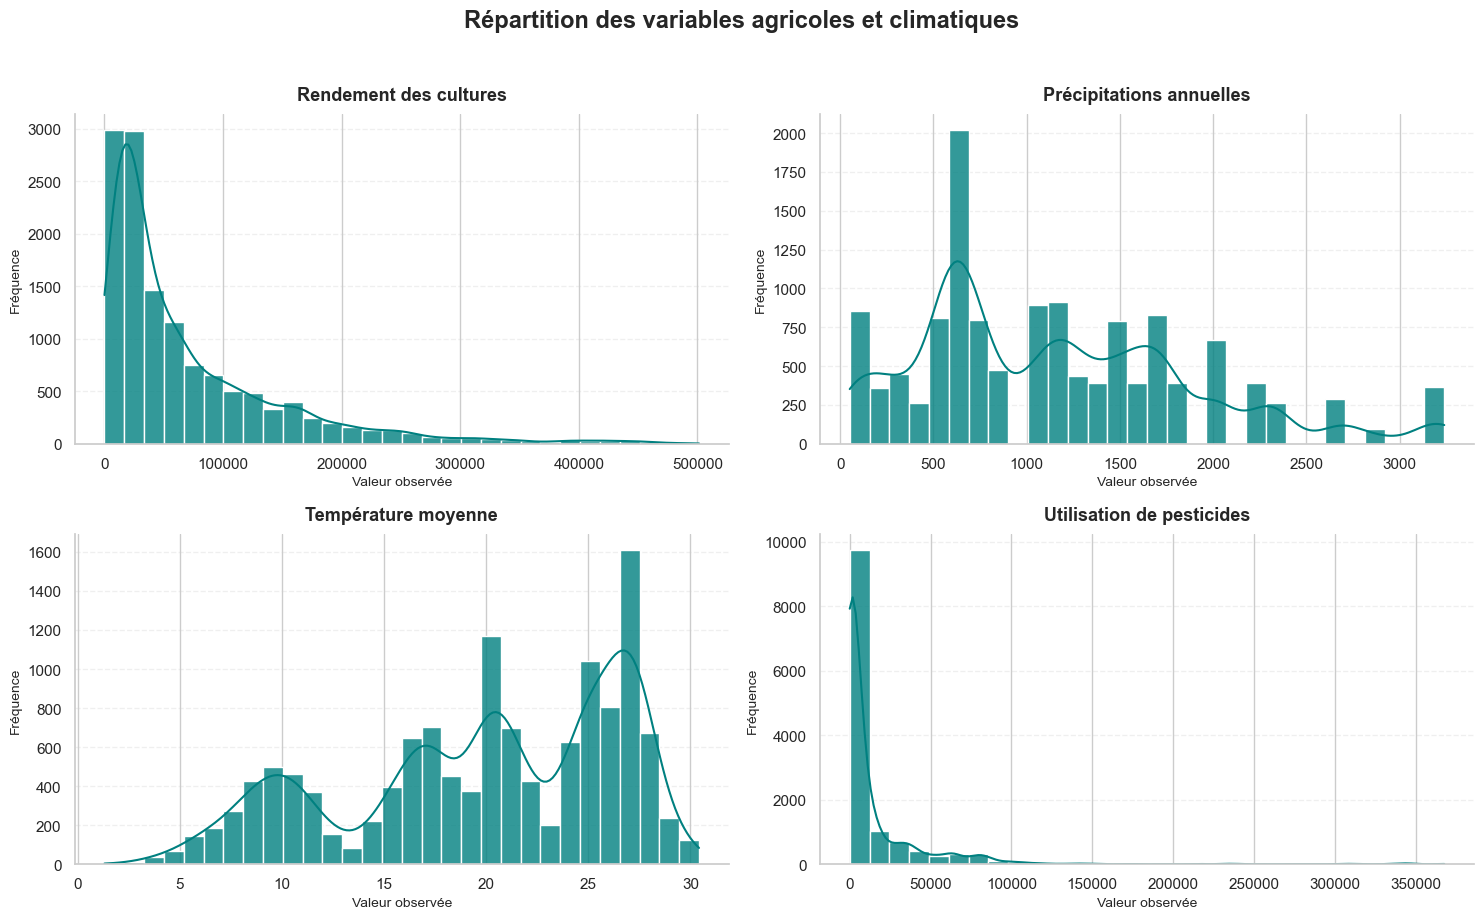

In [159]:
# Détection des valeurs aberrantes via la règle IQR sur les variables numériques

print("=" * 70)
print("6. DETECTION DES OUTLIERS — REGLE IQR")
print("=" * 70)

colonnes_num = ['Yield_crops_hg_per_ha', 'average_rain_fall_mm_per_year', 'Pesticide_totale_use_tonnes', 'avg_temp']

for col in colonnes_num:
    Q1  = yield_df_clean[col].quantile(0.25)
    Q3  = yield_df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    outliers = yield_df_clean[(yield_df_clean[col] < borne_inf) | (yield_df_clean[col] > borne_sup)]

    print(f"\n  {col}")
    print(f"  Q1={Q1:.2f} | Q3={Q3:.2f} | IQR={IQR:.2f}")
    print(f"  Bornes : [{borne_inf:.2f} ; {borne_sup:.2f}]")
    print(f"  Nombre d'outliers : {len(outliers)} ({round(len(outliers)/len(yield_df_clean)*100, 2)}%)")
    print(f"  Min outlier : {outliers[col].min():.2f} | Max outlier : {outliers[col].max():.2f}" if len(outliers) > 0 else "  Aucun outlier")

import matplotlib.pyplot as plt
import seaborn as sns

colonnes_num = [
    'Yield_crops_hg_per_ha',
    'average_rain_fall_mm_per_year',
    'avg_temp',
    'Pesticide_totale_use_tonnes'
]

noms_variables = {
    'Yield_crops_hg_per_ha': 'Rendement des cultures',
    'average_rain_fall_mm_per_year': 'Précipitations annuelles',
    'avg_temp': 'Température moyenne',
    'Pesticide_totale_use_tonnes': 'Utilisation de pesticides'
}

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes = axes.flatten()

for ax, col in zip(axes, colonnes_num):

    donnees = yield_df_clean[col].dropna()

    sns.histplot(
        data=donnees,
        bins=30,
        kde=True,
        ax=ax,
        color="teal",
        edgecolor="white",
        alpha=0.8
    )

    ax.set_title(
        noms_variables[col],
        fontsize=13,
        fontweight="bold",
        pad=10
    )

    ax.set_xlabel("Valeur observée", fontsize=10)
    ax.set_ylabel("Fréquence", fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    sns.despine(ax=ax)

fig.suptitle(
    "Répartition des variables agricoles et climatiques",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

In [165]:

# Export du dataset final nettoyé

from pathlib import Path

print("=" * 70)
print("8. EXPORT DU DATASET FINAL")
print("=" * 70)

# Définir le dossier de sortie
dossier_sortie = Path(r"C:\Users\amela\P12 System recomendation\outputs")

# Créer le dossier s'il n'existe pas
dossier_sortie.mkdir(parents=True, exist_ok=True)

# Exporter le dataset final
chemin_fichier = dossier_sortie / "dataset_final.csv"
yield_df_clean.to_csv(chemin_fichier, index=False, encoding="utf-8-sig")

print(f"Fichier exporté : {chemin_fichier}")

print(f"\nRésumé final :")
print(f"  Dimensions           : {yield_df_clean.shape}")
print(f"  Colonnes             : {list(yield_df_clean.columns)}")
print(f"  Pays                 : {yield_df_clean['Area'].nunique()}")
print(f"  Cultures             : {yield_df_clean['Item'].nunique()}")
print(f"  Période              : {yield_df_clean['Year'].min()} → {yield_df_clean['Year'].max()}")
print(f"  Valeurs manquantes   : {yield_df_clean.isnull().sum().sum()}")

# Vérification de l'export
print(f"\nFichier créé avec succès : {chemin_fichier.exists()}")


8. EXPORT DU DATASET FINAL
Fichier exporté : C:\Users\amela\P12 System recomendation\outputs\dataset_final.csv

Résumé final :
  Dimensions           : (13130, 7)
  Colonnes             : ['Area', 'Item', 'Year', 'Yield_crops_hg_per_ha', 'average_rain_fall_mm_per_year', 'Pesticide_totale_use_tonnes', 'avg_temp']
  Pays                 : 101
  Cultures             : 10
  Période              : 1990 → 2013
  Valeurs manquantes   : 0

Fichier créé avec succès : True


###  Analyse en composant princilap PCA yield_df_clean 

Variance expliquée par composante :
  PC1 : 34.38%  (cumulée : 34.38%)
  PC2 : 28.17%  (cumulée : 62.55%)
  PC3 : 22.54%  (cumulée : 85.09%)
  PC4 : 14.91%  (cumulée : 100.00%)


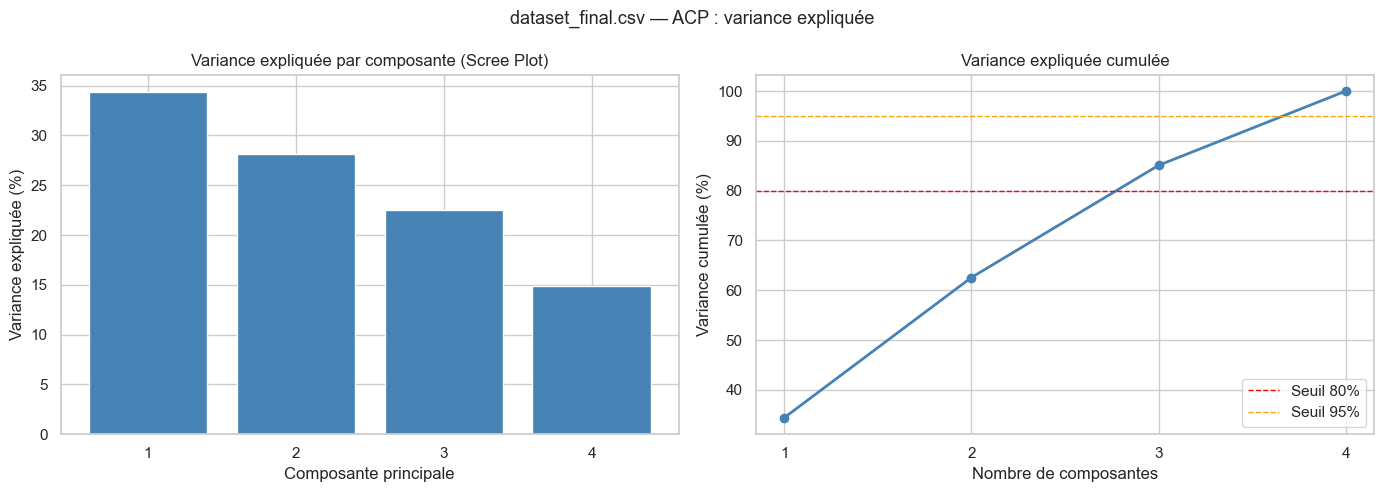


Loadings (contribution des variables aux composantes) :


,Yield_crops_hg_per_ha,average_rain_fall_mm_per_year,Pesticide_totale_use_tonnes,avg_temp
PC1,-0.288,0.618,-0.144,0.717
PC2,0.567,0.442,0.694,-0.015
PC3,0.743,0.082,-0.657,0.096
PC4,0.208,-0.644,0.255,0.690


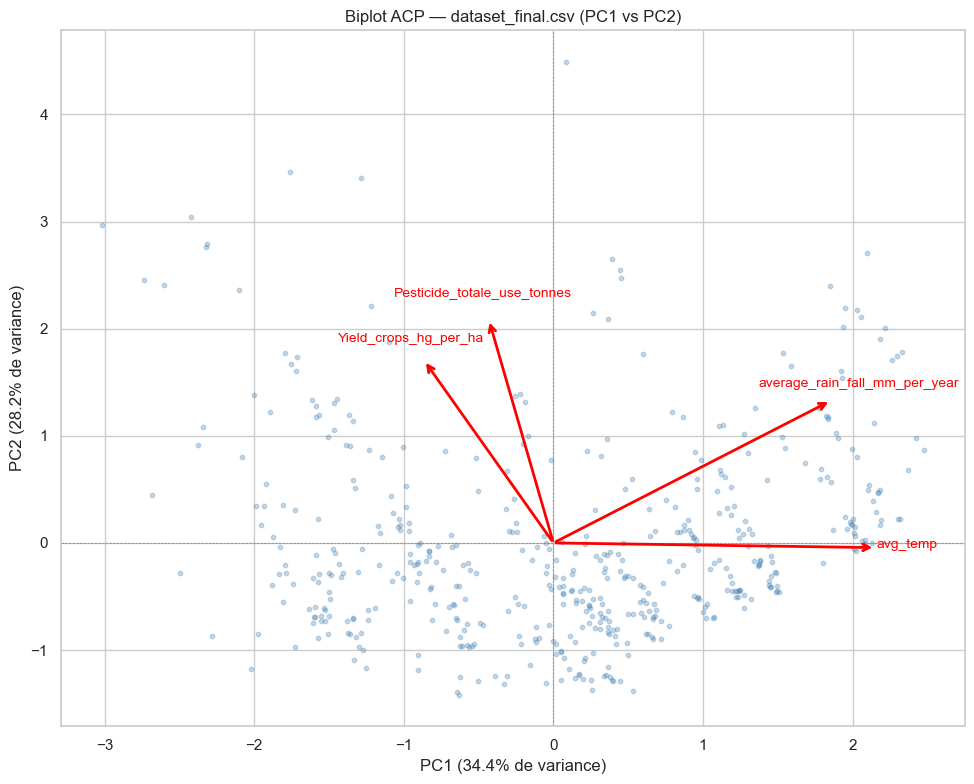

In [199]:
# ACP - yield_df_clean.csv

# Variables numériques retenues pour l'ACP
colonnes_acp = ['Yield_crops_hg_per_ha', 'average_rain_fall_mm_per_year', 'Pesticide_totale_use_tonnes', 'avg_temp']

# Standardisation
scaler = StandardScaler()
X_scaled = scaler.fit_transform(yield_df_clean[colonnes_acp])

# Application de la PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Variance expliquée
variance_expliquee = pca.explained_variance_ratio_
variance_cumulee   = np.cumsum(variance_expliquee)

print("Variance expliquée par composante :")
for i, (var, cum) in enumerate(zip(variance_expliquee, variance_cumulee)):
    print(f"  PC{i+1} : {var*100:.2f}%  (cumulée : {cum*100:.2f}%)")

# Scree plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, len(variance_expliquee)+1), variance_expliquee * 100, color='steelblue')
axes[0].set_title('Variance expliquée par composante (Scree Plot)')
axes[0].set_xlabel('Composante principale')
axes[0].set_ylabel('Variance expliquée (%)')
axes[0].set_xticks(range(1, len(variance_expliquee)+1))

axes[1].plot(range(1, len(variance_cumulee)+1), variance_cumulee * 100,
             marker='o', color='steelblue', linewidth=2)
axes[1].axhline(y=80, color='red', linestyle='--', linewidth=1, label='Seuil 80%')
axes[1].axhline(y=95, color='orange', linestyle='--', linewidth=1, label='Seuil 95%')
axes[1].set_title('Variance expliquée cumulée')
axes[1].set_xlabel('Nombre de composantes')
axes[1].set_ylabel('Variance cumulée (%)')
axes[1].set_xticks(range(1, len(variance_cumulee)+1))
axes[1].legend()

plt.suptitle('dataset_final.csv — ACP : variance expliquée', fontsize=13)
plt.tight_layout()
plt.show()

# Loadings (contributions des variables aux composantes)
loadings = pca.components_
print("\nLoadings (contribution des variables aux composantes) :")
loadings_df = pd.DataFrame(
    loadings,
    columns=colonnes_acp,
    index=[f'PC{i+1}' for i in range(len(loadings))]
)
display(loadings_df.round(3))

# Biplot PC1 / PC2
fig, ax = plt.subplots(figsize=(10, 8))

# Projection des individus (échantillon de 500 pour la lisibilité)
sample_idx = np.random.choice(len(X_pca), size=500, replace=False)
ax.scatter(X_pca[sample_idx, 0], X_pca[sample_idx, 1],
           alpha=0.3, s=10, color='steelblue', label='Observations')

# Projection des variables
scale = 3
for i, var in enumerate(colonnes_acp):
    ax.annotate('', xy=(loadings[0, i] * scale, loadings[1, i] * scale),
                xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='red', lw=2))
    ax.text(loadings[0, i] * scale * 1.1, loadings[1, i] * scale * 1.1,
            var, color='red', fontsize=10, ha='center')

ax.axhline(0, color='grey', linewidth=0.5, linestyle='--')
ax.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax.set_xlabel(f'PC1 ({variance_expliquee[0]*100:.1f}% de variance)')
ax.set_ylabel(f'PC2 ({variance_expliquee[1]*100:.1f}% de variance)')
ax.set_title('Biplot ACP — dataset_final.csv (PC1 vs PC2)')
plt.tight_layout()
plt.show()

#### Crop_yield.csv

1. DOUBLONS
Nombre de lignes dupliquées (toutes colonnes) : 0
Soit 0.0% du dataset

2. VALEURS MANQUANTES
Region                    0
Soil_Type                 0
Crop                      0
Rainfall_mm               0
Temperature_Celsius       0
Fertilizer_Used           0
Irrigation_Used           0
Weather_Condition         0
Days_to_Harvest           0
Yield_tons_per_hectare    0
dtype: int64

Taux de NA global : 0.0%

3. TYPES DE COLONNES
Region                     object
Soil_Type                  object
Crop                       object
Rainfall_mm               float64
Temperature_Celsius       float64
Fertilizer_Used              bool
Irrigation_Used              bool
Weather_Condition          object
Days_to_Harvest             int64
Yield_tons_per_hectare    float64
dtype: object

4. STATISTIQUES DESCRIPTIVES


,Rainfall_mm,Temperature_Celsius,Days_to_Harvest,Yield_tons_per_hectare
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,549.981901,27.504965,104.495025,4.649472
std,259.851320,7.220608,25.953412,1.696572
min,100.000896,15.000034,60.000000,-1.147613
25%,324.891090,21.254502,82.000000,3.417637
50%,550.124061,27.507365,104.000000,4.651808
75%,774.738520,33.753267,127.000000,5.879200
max,999.998098,39.999997,149.000000,9.963372



5. DETECTION DES OUTLIERS — REGLE IQR

  Rainfall_mm
  Q1=324.89 | Q3=774.74 | IQR=449.85
  Bornes : [-349.88 ; 1449.51]
  Nombre d'outliers : 0 (0.0%)
  Aucun outlier

  Temperature_Celsius
  Q1=21.25 | Q3=33.75 | IQR=12.50
  Bornes : [2.51 ; 52.50]
  Nombre d'outliers : 0 (0.0%)
  Aucun outlier

  Days_to_Harvest
  Q1=82.00 | Q3=127.00 | IQR=45.00
  Bornes : [14.50 ; 194.50]
  Nombre d'outliers : 0 (0.0%)
  Aucun outlier

  Yield_tons_per_hectare
  Q1=3.42 | Q3=5.88 | IQR=2.46
  Bornes : [-0.27 ; 9.57]
  Nombre d'outliers : 84 (0.01%)
  Min outlier : -1.15 | Max outlier : 9.96

6. VALEURS NEGATIVES SUR LA VARIABLE CIBLE
Nombre de valeurs négatives : 231 (0.02%)


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
756,East,Peaty,Cotton,101.019421,33.804131,False,False,Rainy,117,-0.007103
7799,South,Chalky,Rice,108.804894,18.004082,False,False,Sunny,86,-0.061283
8421,East,Chalky,Soybean,168.120735,38.473430,False,False,Cloudy,111,-0.119911
9553,North,Silt,Wheat,156.607973,16.610257,False,False,Sunny,129,-0.193093
15435,South,Chalky,Maize,177.481344,27.719742,False,False,Sunny,94,-0.009811



--- Visualisation ---


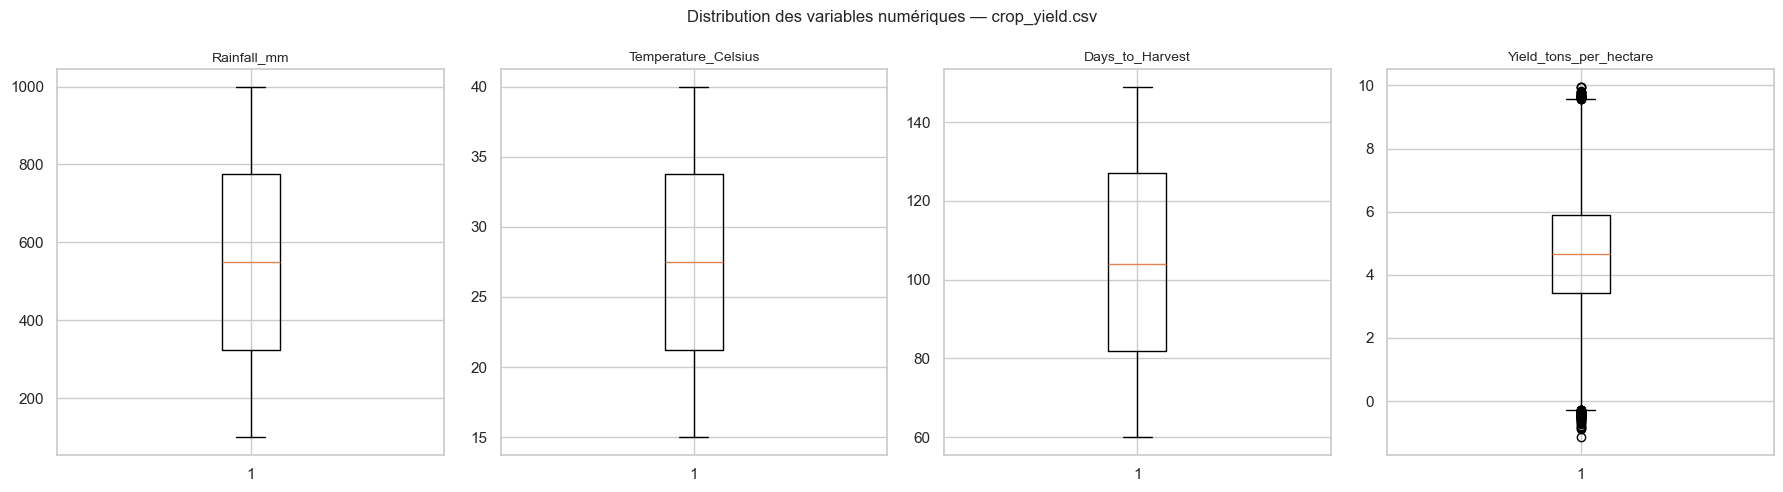

In [172]:
# Exploration et nettoyage de crop_yield.csv

print("=" * 70)
print("1. DOUBLONS")
print("=" * 70)
total_doublons = df_crop_yield.duplicated().sum()
print(f"Nombre de lignes dupliquées (toutes colonnes) : {total_doublons}")
print(f"Soit {round(total_doublons / len(df_crop_yield) * 100, 2)}% du dataset")

print("\n" + "=" * 70)
print("2. VALEURS MANQUANTES")
print("=" * 70)
print(df_crop_yield.isnull().sum())
print(f"\nTaux de NA global : {round(df_crop_yield.isnull().sum().sum() / df_crop_yield.size * 100, 2)}%")

print("\n" + "=" * 70)
print("3. TYPES DE COLONNES")
print("=" * 70)
print(df_crop_yield.dtypes)

print("\n" + "=" * 70)
print("4. STATISTIQUES DESCRIPTIVES")
print("=" * 70)
display(df_crop_yield.describe())

print("\n" + "=" * 70)
print("5. DETECTION DES OUTLIERS — REGLE IQR")
print("=" * 70)
colonnes_num = ['Rainfall_mm', 'Temperature_Celsius', 'Days_to_Harvest', 'Yield_tons_per_hectare']

for col in colonnes_num:
    Q1  = df_crop_yield[col].quantile(0.25)
    Q3  = df_crop_yield[col].quantile(0.75)
    IQR = Q3 - Q1
    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR
    outliers  = df_crop_yield[(df_crop_yield[col] < borne_inf) | (df_crop_yield[col] > borne_sup)]
    print(f"\n  {col}")
    print(f"  Q1={Q1:.2f} | Q3={Q3:.2f} | IQR={IQR:.2f}")
    print(f"  Bornes : [{borne_inf:.2f} ; {borne_sup:.2f}]")
    print(f"  Nombre d'outliers : {len(outliers)} ({round(len(outliers)/len(df_crop_yield)*100, 2)}%)")
    if len(outliers) > 0:
        print(f"  Min outlier : {outliers[col].min():.2f} | Max outlier : {outliers[col].max():.2f}")
    else:
        print(f"  Aucun outlier")

print("\n" + "=" * 70)
print("6. VALEURS NEGATIVES SUR LA VARIABLE CIBLE")
print("=" * 60)
valeurs_neg = df_crop_yield[df_crop_yield['Yield_tons_per_hectare'] < 0]
print(f"Nombre de valeurs négatives : {len(valeurs_neg)} ({round(len(valeurs_neg)/len(df_crop_yield)*100, 2)}%)")
display(valeurs_neg.head())

print("\n--- Visualisation ---")
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for i, col in enumerate(colonnes_num):
    axes[i].boxplot(df_crop_yield[col].dropna(), vert=True)
    axes[i].set_title(col, fontsize=10)
plt.suptitle("Distribution des variables numériques — crop_yield.csv", fontsize=12)
plt.tight_layout()
plt.show()

In [176]:
# Suppression des valeurs négatives sur Yield_tons_per_hectare

print("=" * 70)
print("7. SUPPRESSION DES VALEURS NEGATIVES")
print("=" * 70)

print(f"Dimensions avant : {df_crop_yield.shape}")
df_crop_yield_clean = df_crop_yield[df_crop_yield['Yield_tons_per_hectare'] >= 0].copy()
print(f"Dimensions après : {df_crop_yield_clean.shape}")
print(f"Lignes supprimées : {len(df_crop_yield) - len(df_crop_yield_clean)}")
print(f"Valeurs négatives résiduelles : {(df_crop_yield_clean['Yield_tons_per_hectare'] < 0).sum()}")

7. SUPPRESSION DES VALEURS NEGATIVES
Dimensions avant : (1000000, 10)
Dimensions après : (999769, 10)
Lignes supprimées : 231
Valeurs négatives résiduelles : 0


####  PCA df_crop_yield_clean

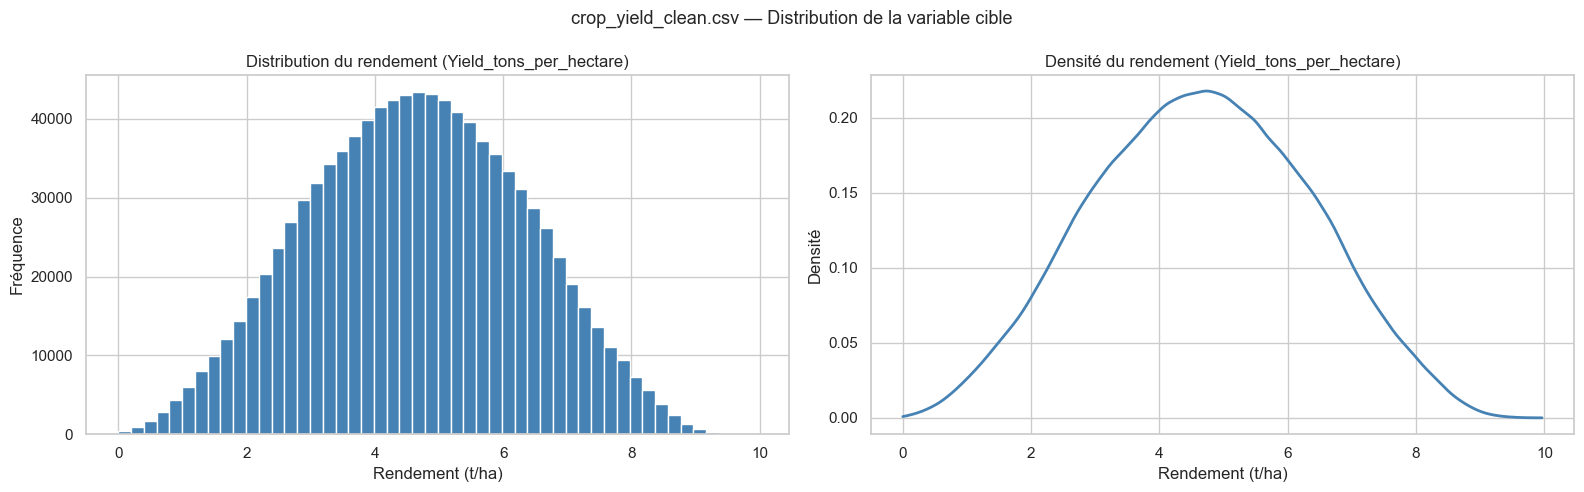

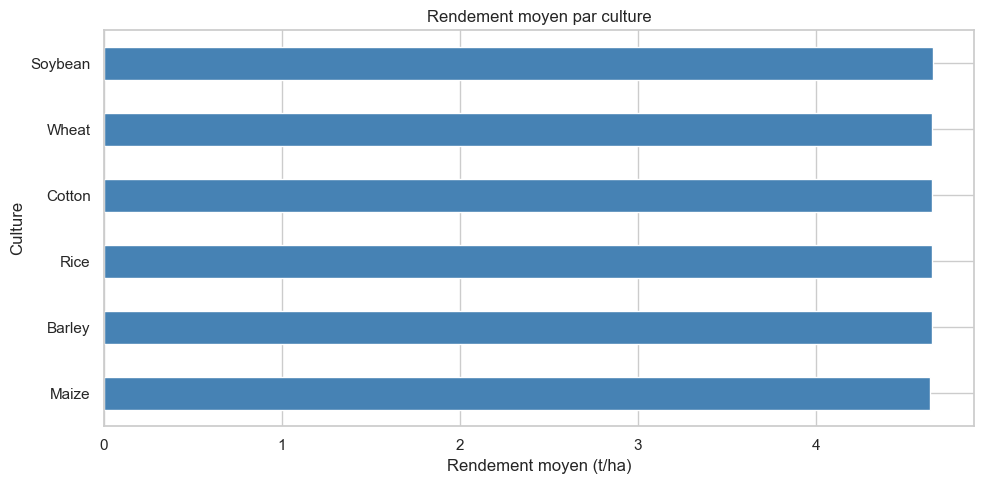

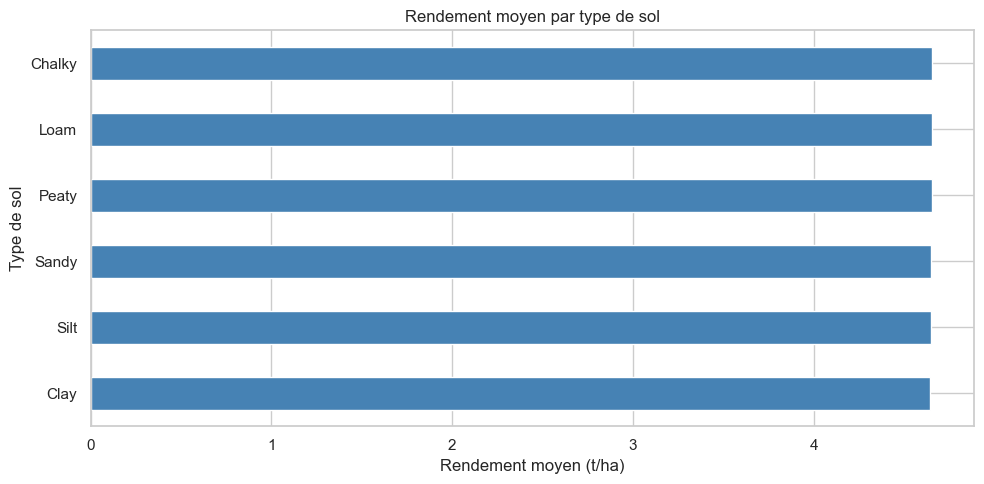

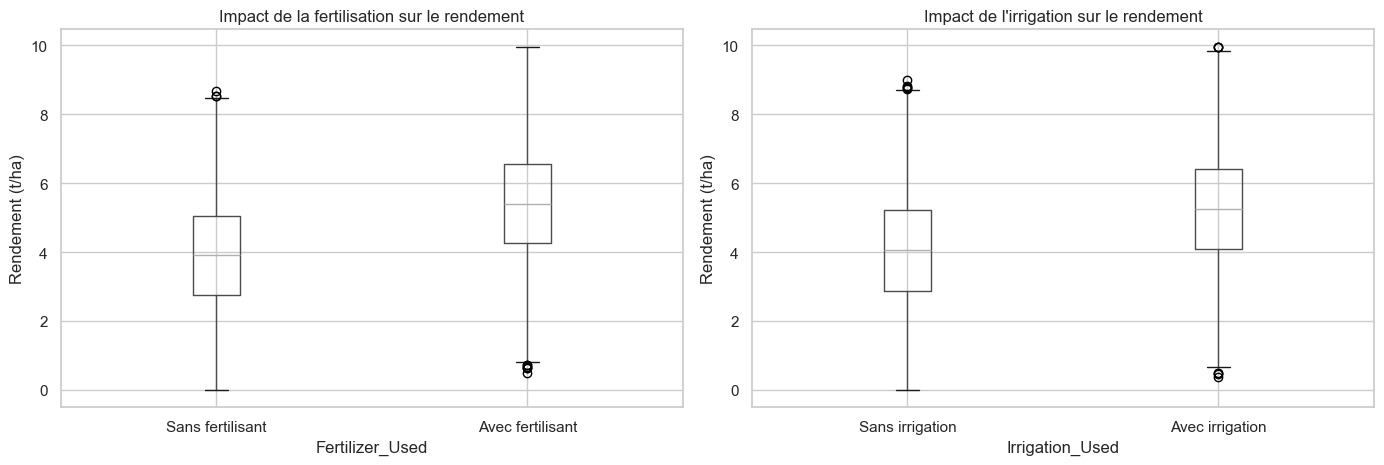

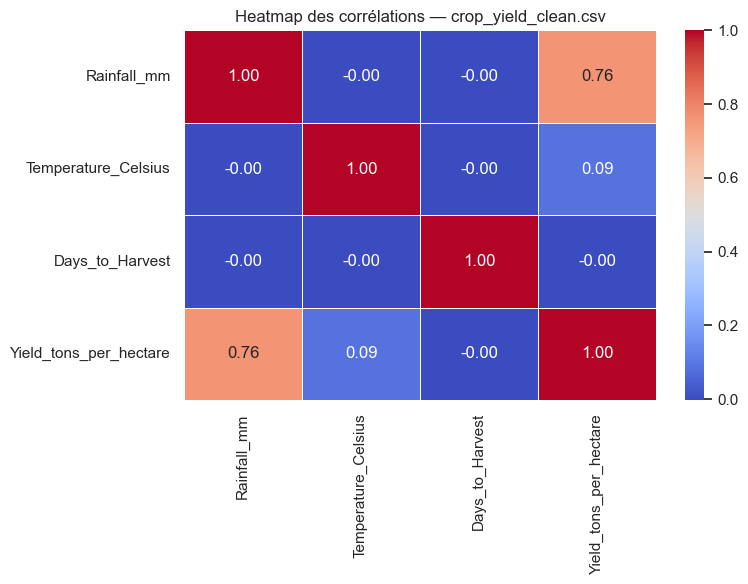

In [189]:
# VISUALISATIONS EXPLORATOIRES
# crop_yield_clean.csv

# Distribution de Yield_tons_per_hectare
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(df_crop_yield_clean['Yield_tons_per_hectare'], bins=50,
             color='steelblue', edgecolor='white')
axes[0].set_title('Distribution du rendement (Yield_tons_per_hectare)')
axes[0].set_xlabel('Rendement (t/ha)')
axes[0].set_ylabel('Fréquence')

data_cy = df_crop_yield_clean['Yield_tons_per_hectare'].dropna()
kde_cy  = gaussian_kde(data_cy)
x_cy    = np.linspace(data_cy.min(), data_cy.max(), 300)
axes[1].plot(x_cy, kde_cy(x_cy), color='steelblue', linewidth=2)
axes[1].set_title('Densité du rendement (Yield_tons_per_hectare)')
axes[1].set_xlabel('Rendement (t/ha)')
axes[1].set_ylabel('Densité')

plt.suptitle('crop_yield_clean.csv — Distribution de la variable cible', fontsize=13)
plt.tight_layout()
plt.show()

# Rendement moyen par culture
fig, ax = plt.subplots(figsize=(10, 5))
rendement_crop = df_crop_yield_clean.groupby('Crop')['Yield_tons_per_hectare'].mean().sort_values()
rendement_crop.plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Rendement moyen par culture')
ax.set_xlabel('Rendement moyen (t/ha)')
ax.set_ylabel('Culture')
plt.tight_layout()
plt.show()

# Rendement moyen par type de sol
fig, ax = plt.subplots(figsize=(10, 5))
rendement_sol = df_crop_yield_clean.groupby('Soil_Type')['Yield_tons_per_hectare'].mean().sort_values()
rendement_sol.plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Rendement moyen par type de sol')
ax.set_xlabel('Rendement moyen (t/ha)')
ax.set_ylabel('Type de sol')
plt.tight_layout()
plt.show()

# Impact de Fertilizer_Used et Irrigation_Used sur le rendement
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_crop_yield_clean.boxplot(column='Yield_tons_per_hectare', by='Fertilizer_Used',
                         ax=axes[0])
axes[0].set_title('Impact de la fertilisation sur le rendement')
axes[0].set_xlabel('Fertilizer_Used')
axes[0].set_ylabel('Rendement (t/ha)')
plt.sca(axes[0])
plt.xticks([1, 2], ['Sans fertilisant', 'Avec fertilisant'])

df_crop_yield_clean.boxplot(column='Yield_tons_per_hectare', by='Irrigation_Used',
                         ax=axes[1])
axes[1].set_title("Impact de l'irrigation sur le rendement")
axes[1].set_xlabel('Irrigation_Used')
axes[1].set_ylabel('Rendement (t/ha)')
plt.sca(axes[1])
plt.xticks([1, 2], ['Sans irrigation', 'Avec irrigation'])

plt.suptitle('')
plt.tight_layout()
plt.show()

# Heatmap des corrélations (variables numériques uniquement)
fig, ax = plt.subplots(figsize=(8, 6))
colonnes_num_cy = ['Rainfall_mm', 'Temperature_Celsius', 'Days_to_Harvest',
                   'Yield_tons_per_hectare']
corr_cy = df_crop_yield_clean[colonnes_num_cy].corr()
sns.heatmap(corr_cy, annot=True, fmt='.2f', cmap='coolwarm',
            ax=ax, linewidths=0.5)
ax.set_title('Heatmap des corrélations — crop_yield_clean.csv')
plt.tight_layout()
plt.show()

### PSA

Region : {'East': 0, 'North': 1, 'South': 2, 'West': 3}
Soil_Type : {'Chalky': 0, 'Clay': 1, 'Loam': 2, 'Peaty': 3, 'Sandy': 4, 'Silt': 5}
Crop : {'Barley': 0, 'Cotton': 1, 'Maize': 2, 'Rice': 3, 'Soybean': 4, 'Wheat': 5}
Weather_Condition : {'Cloudy': 0, 'Rainy': 1, 'Sunny': 2}

Variance expliquée par composante :
  PC1 : 19.54%  (cumulée : 19.54%)
  PC2 : 10.04%  (cumulée : 29.58%)
  PC3 : 10.04%  (cumulée : 39.62%)
  PC4 : 10.01%  (cumulée : 49.63%)
  PC5 : 10.01%  (cumulée : 59.64%)
  PC6 : 9.99%  (cumulée : 69.64%)
  PC7 : 9.98%  (cumulée : 79.62%)
  PC8 : 9.97%  (cumulée : 89.59%)
  PC9 : 9.96%  (cumulée : 99.56%)
  PC10 : 0.44%  (cumulée : 100.00%)


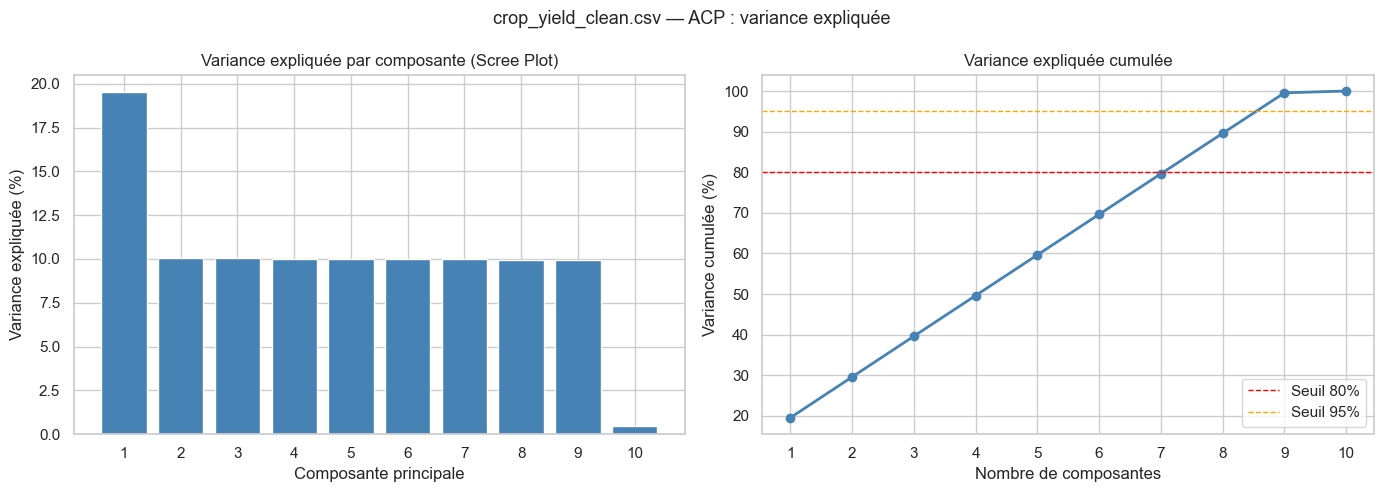


Loadings (contribution des variables aux composantes) :


,Rainfall_mm,Temperature_Celsius,Days_to_Harvest,Yield_tons_per_hectare,Region_enc,Soil_Type_enc,Crop_enc,Weather_Condition_enc,Fertilizer_Used_enc,Irrigation_Used_enc
PC1,0.566,0.064,-0.004,0.707,0.001,-0.000,0.002,0.002,0.327,0.262
PC2,-0.456,0.448,0.029,-0.001,0.232,0.154,0.269,-0.346,0.517,0.231
PC3,-0.136,0.077,0.208,0.001,-0.452,0.577,-0.150,0.520,0.303,-0.101
PC4,-0.125,-0.473,0.538,0.002,-0.353,-0.043,0.261,-0.235,-0.061,0.466
PC5,0.322,0.163,0.284,0.000,-0.008,0.286,0.605,-0.203,-0.173,-0.519
PC6,0.036,0.351,0.607,0.003,-0.101,-0.369,-0.493,-0.205,0.084,-0.261
PC7,-0.015,-0.383,0.403,0.001,0.750,0.130,-0.065,0.265,0.171,-0.086
PC8,0.106,0.213,0.083,0.001,0.183,0.579,-0.363,-0.271,-0.496,0.343
PC9,-0.021,0.468,0.221,-0.001,0.106,-0.266,0.302,0.573,-0.333,0.346
PC10,-0.566,-0.063,-0.000,0.707,0.000,0.000,0.000,-0.000,-0.327,-0.262


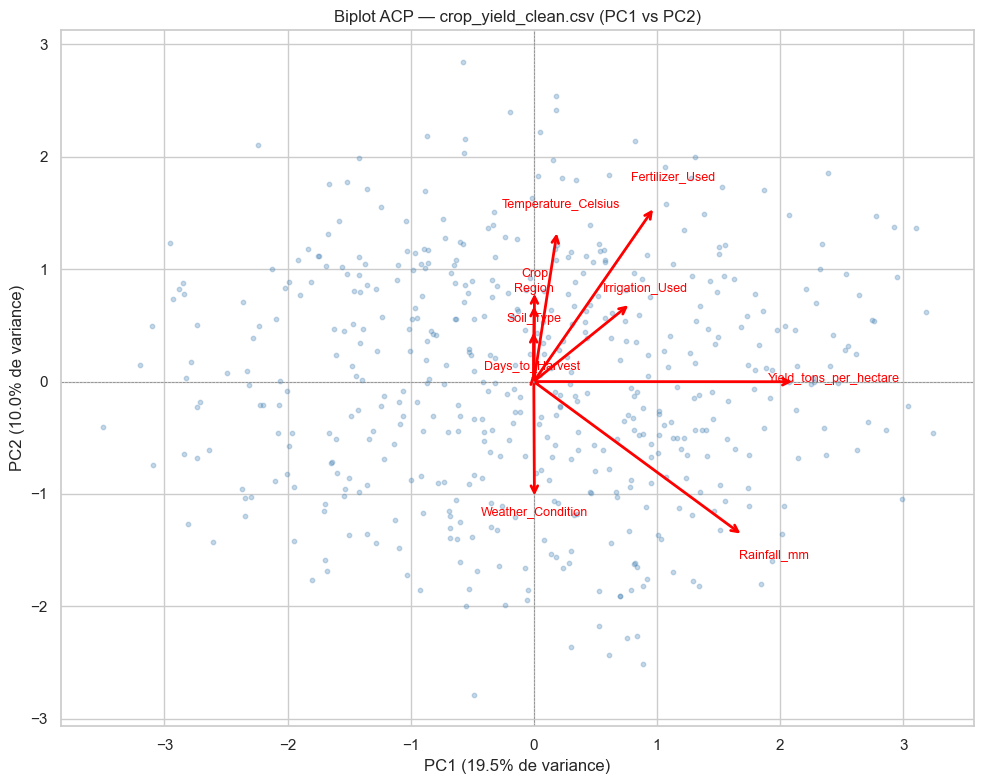

In [194]:
# ACP - crop_yield_clean.csv

# Encodage des variables catégorielles et booléennes
crop_yield_acp = crop_yield_clean.copy()

colonnes_cat = ['Region', 'Soil_Type', 'Crop', 'Weather_Condition']
for col in colonnes_cat:
    le = LabelEncoder()
    crop_yield_acp[col + '_enc'] = le.fit_transform(crop_yield_acp[col])
    print(f"{col} : {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Conversion des booléens en entiers
crop_yield_acp['Fertilizer_Used_enc'] = crop_yield_acp['Fertilizer_Used'].astype(int)
crop_yield_acp['Irrigation_Used_enc'] = crop_yield_acp['Irrigation_Used'].astype(int)

# Variables retenues pour l'ACP
colonnes_acp_cy = [
    'Rainfall_mm', 'Temperature_Celsius', 'Days_to_Harvest',
    'Yield_tons_per_hectare', 'Region_enc', 'Soil_Type_enc',
    'Crop_enc', 'Weather_Condition_enc',
    'Fertilizer_Used_enc', 'Irrigation_Used_enc'
]

# Standardisation
scaler_cy = StandardScaler()
X_scaled_cy = scaler_cy.fit_transform(crop_yield_acp[colonnes_acp_cy])

# Application de la PCA
pca_cy = PCA()
X_pca_cy = pca_cy.fit_transform(X_scaled_cy)

# Variance expliquée
variance_expliquee_cy = pca_cy.explained_variance_ratio_
variance_cumulee_cy   = np.cumsum(variance_expliquee_cy)

print("\nVariance expliquée par composante :")
for i, (var, cum) in enumerate(zip(variance_expliquee_cy, variance_cumulee_cy)):
    print(f"  PC{i+1} : {var*100:.2f}%  (cumulée : {cum*100:.2f}%)")

# Scree plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, len(variance_expliquee_cy)+1),
            variance_expliquee_cy * 100, color='steelblue')
axes[0].set_title('Variance expliquée par composante (Scree Plot)')
axes[0].set_xlabel('Composante principale')
axes[0].set_ylabel('Variance expliquée (%)')
axes[0].set_xticks(range(1, len(variance_expliquee_cy)+1))

axes[1].plot(range(1, len(variance_cumulee_cy)+1), variance_cumulee_cy * 100,
             marker='o', color='steelblue', linewidth=2)
axes[1].axhline(y=80, color='red', linestyle='--', linewidth=1, label='Seuil 80%')
axes[1].axhline(y=95, color='orange', linestyle='--', linewidth=1, label='Seuil 95%')
axes[1].set_title('Variance expliquée cumulée')
axes[1].set_xlabel('Nombre de composantes')
axes[1].set_ylabel('Variance cumulée (%)')
axes[1].set_xticks(range(1, len(variance_cumulee_cy)+1))
axes[1].legend()

plt.suptitle('crop_yield_clean.csv — ACP : variance expliquée', fontsize=13)
plt.tight_layout()
plt.show()

# Loadings
loadings_cy = pca_cy.components_
loadings_cy_df = pd.DataFrame(
    loadings_cy,
    columns=colonnes_acp_cy,
    index=[f'PC{i+1}' for i in range(len(loadings_cy))]
)
print("\nLoadings (contribution des variables aux composantes) :")
display(loadings_cy_df.round(3))

# Biplot PC1 / PC2
fig, ax = plt.subplots(figsize=(10, 8))

sample_idx = np.random.choice(len(X_pca_cy), size=500, replace=False)
ax.scatter(X_pca_cy[sample_idx, 0], X_pca_cy[sample_idx, 1],
           alpha=0.3, s=10, color='steelblue')

scale = 3
for i, var in enumerate(colonnes_acp_cy):
    ax.annotate('', xy=(loadings_cy[0, i] * scale, loadings_cy[1, i] * scale),
                xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='red', lw=2))
    ax.text(loadings_cy[0, i] * scale * 1.15, loadings_cy[1, i] * scale * 1.15,
            var.replace('_enc', ''), color='red', fontsize=9, ha='center')

ax.axhline(0, color='grey', linewidth=0.5, linestyle='--')
ax.axvline(0, color='grey', linewidth=0.5, linestyle='--')
ax.set_xlabel(f'PC1 ({variance_expliquee_cy[0]*100:.1f}% de variance)')
ax.set_ylabel(f'PC2 ({variance_expliquee_cy[1]*100:.1f}% de variance)')
ax.set_title('Biplot ACP — crop_yield_clean.csv (PC1 vs PC2)')
plt.tight_layout()
plt.show()